# Searching for a hidden algorithm switch in code models: one DAS protocol, seven controls (demo)

**The question (claim K2).** Asked for the number of connected components of a graph, Qwen3-8B almost always writes **union-find**. It writes BFS or DFS only when the prompt asks for them. Is there a **low-rank causal variable** inside the model, a linear subspace that *is* the algorithm decision? Or is there only a **steering handle**, a direction that changes the output without being the model's own variable?

**The protocol.** It was committed and hash-chained before any GPU use, and is identical at every site:
- **Decision token d.** The canonical opening ```` ```python\ndef solve(n, edges):\n ```` + indent + ` def` is prefilled. The next token names the helper (`' bfs'`, `' dfs'`, `' find'` ...), so the class distribution at d is the model's algorithm choice.
- **Map class.** A linear orthonormal `R` (d_model x 8, nested ranks k = 1/2/4/8).
- **Interchange.** `h <- h + R Rᵀ(h_src - h_base)` on the output of block L at d. The source is a *forced* prompt ("Implement BFS for this task."); the base is a *neutral twin* with the same number of tokens.
- **Objective and readout.** A bounded KL from the source's own class distribution. The readout is the margin `log P(c_src) - log P(c_base)`.
- **Recovery** = mean Δmargin(DAS) / mean Δmargin(full-state exchange) on held-out pairs. A held-out pair needs a held-out template family *and* a held-out noun.
- **Seven controls**, with thresholds fixed before any fit: c1 random subspaces, c2 label-permuted refits, c3 a randomly initialised network, c4 reverse interchange, c5/c6 natural-variance subspace, c7 seed stability.

**What the artifact found.** K2 is **disconfirmed** (p_K2 = 0.037). A rank-4 edit at one token steers Qwen3-8B: 29/30 correct DFS programs, against 0/30 for a random subspace. It is not a certified variable:
- label-permuted maps keep 63-87% of the effect (c2 limit: 10%);
- a random-init network keeps 69% (c3 limit: 25%);
- the edit overshoots the full-state exchange 8x (OFF-MANIFOLD);
- BFS edits give 29/30 BFS attempts, but only 5 programs pass the hidden tests.

**What this notebook runs.**
- **Part 1 (CPU, seconds).** The artifact's analysis stage (`src/analysis8.py`, `src/digest8.py`, `src/stats8.py`) on the **recorded** Qwen3-8B generation cells of the T10 decision site, the one dataset shipped in `mini_demo_data.json`. It rebuilds the generation table, the V0 checks, the verdict and the K2 status.
- **Part 2 (CPU, minutes).** The DAS code itself (`src/engine8.py`, `src/das8.py`, `src/run_dec.py`, `src/run_rinit.py`) **live at toy scale on Qwen3-0.6B**. It runs the decision-site caches, the unit tests, the block scan, the fits, controls c1-c7 and the baselines. Qwen3-0.6B shares Qwen3-8B's tokenizer, so the recorded prompt token ids and class tokens are used unchanged.
- **Results.** A summary table and figures: generation outcomes, recovery by rank against random subspaces, control ratios, the block scan, and the actual activation geometry of the fitted subspace.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install (every src/ module of the artifact logs with it)
_pip('loguru==0.7.3')

# numpy, scipy, scikit-learn, matplotlib, torch, transformers — pre-installed on Colab, install locally only, at
# Colab's exact versions (the artifact pinned torch 2.8.0 + transformers 4.57.6; the calls used here exist in both)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'matplotlib==3.10.0')
    _pip('torch==2.9.0', '--index-url', 'https://download.pytorch.org/whl/cpu')
    _pip('transformers==5.0.0', 'tokenizers==0.22.2', 'huggingface_hub==1.4.0')

In [2]:
from __future__ import annotations

# --- method.py (the orchestrator) ---
import argparse
import subprocess
import sys
from pathlib import Path

# --- src/cfg8.py, src/stats8.py, src/analysis8.py, src/digest8.py ---
import hashlib
import json
import math
import os
import resource
from datetime import datetime, timezone
from typing import Any, Callable, Iterable, Iterator

import numpy as np
from loguru import logger
from scipy import stats

# --- src/engine8.py, src/das8.py, src/run_dec.py, src/run_rinit.py ---
import gc
import time
from contextlib import contextmanager

import torch

# --- src/figures8.py (its matplotlib.use("Agg") is dropped: the notebook draws inline) ---
import matplotlib
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import MDS, Isomap

# --- notebook addition: render the digest tables as markdown ---
from IPython.display import Markdown, display

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-8/experiment-40/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
_m = data["metadata"]
print(_m["source_artifact"])
print("dataset:", _m["dataset"], "|", _m["n_examples"], "CRN slots |", len(_m["live"]["prompts"]),
      "prompt records for the live replay")
print(_m["note"])

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
art_e-_q5mSJGrSb (iteration 8, experiment 40): one DAS protocol at the decision token of Qwen3-8B (T10) and gemma-3-4b-it (GRID), seven committed controls
dataset: T10_dec_generation | 60 CRN slots | 66 prompt records for the live replay
T10 decision site of Qwen3-8B (L* = 22, k* = 4): all 60 CRN generation slots (30 per off-default target class, bfs and dfs); predict_<ARM> = '<label>|<pass|fail>' from the frozen labellers and the hidden tests


## Config

Every knob that was shrunk for the demo lives here, with the original value in the comment. Part 1 is fixed by the shipped data; Part 2 is a live toy-scale replay.

**How the values were chosen.** All three runtimes are for the whole notebook on 2 CPU cores, install cell included.

| run | settings | runtime |
|---|---|---|
| minimum | `SCAN_STEPS` 5, `FIT_STEPS` 10, `FIT_SEEDS` (0, 1), one held source per class, 5 random subspaces, `N_BOOT` 200 | 315 s |
| round 1 | step counts doubled; `N_BOOT` and `N_RANDOM_SHARES` back to the originals | 399 s |
| round 2 | two held sources per class, the original three seeds, 10 random subspaces | 458 s |

Scaling stopped there, to stay inside a 10-minute budget. With 10 fit steps the maps were clearly under-fitted (held-out recovery 0.46); with 20 steps it is 1.28.

**To scale further,** raise the prompt counts (up to what `mini_demo_data.json` ships) and the step counts. The original values are `FIT_STEPS = 240`, `SCAN_STEPS = 100` and `N_RANDOM_SUBSPACES = 50`. The full experiment is the artifact's `method.py` on a GPU with Qwen3-8B.

In [5]:
# ---------------- Part 1: analysis of the recorded Qwen3-8B generation cells (CPU, seconds) ----------------
# Fixed by the shipped data: all 60 CRN slots of the T10 decision site (L* = 22, k* = 4), 30 per off-default target
# class (bfs, dfs). Original: analysis8.py also reads the T10 band cells, the GRID cells and the mediation rows.

# ---------------- Part 2: live DAS at the decision token, toy scale (CPU, minutes) ----------------
LIVE_MODEL_ID = "Qwen/Qwen3-0.6B"  # original: "Qwen/Qwen3-8B" @ b968826d (bf16, one 23 GB L4); same tokenizer
N_SRC_TRAIN_PER_FAM = 1     # forced train prompts per (class, template family 0-2); shipped: 2; original: 4 (12 per class)
N_SRC_HELD_PER_CLASS = 2    # forced held prompts per class (families 3-4); shipped: 4; original: 8 per class
N_TWINS_TRAIN = 2           # neutral train twins (bases); shipped: 8; original: 66 train twins + 36 train padding twins
N_TWINS_HELD = 2            # neutral held twins (bases); shipped: 6; original: 20 held twins + 24 held padding twins
USE_PLACEMENT_PROMPTS = True  # bans, seed strings, novelty instructions, empty spec: states only, for the geometry
SCAN_STEPS = 10             # original: 100 (cfg8.SCAN_STEPS: the rank-1 fit per block and fold of the scan)
FIT_STEPS = 20              # original: 240 (cfg8.FIT_STEPS: main fits, rank-1-only fit, label controls, c3)
FIT_SEEDS = (0, 1, 2)       # original: (0, 1, 2) (c7 needs at least two seeds)
VAL_EVERY = 10              # original: 20 (validation every n steps; early stop after 3 checks without improvement)
U9_STEPS = 10               # original: 20 (unit test U9: mini fit)
N_RANDOM_SUBSPACES = 10     # original: 50 (c1: Haar-random subspaces per rank)
N_RANDOM_SHARES = 1000      # original: 1000 (random references of the c6 variance share and the c7 principal cosine)
N_BOOT = 2000               # original: 2000 (two-way cluster bootstrap resamples)
RUN_C3 = True               # c3 (src/run_rinit.py): refit on a randomly initialised copy of the live model
RUN_FULL_PIPELINE = False   # True = run the original method.py (repo checkout, Qwen3-8B + gemma-3-4b-it, GPU)

## The original pipeline: `method.py`

`method.py` is the artifact's entry point. It runs every stage in order, each in its own process, because the GPU holds one model at a time. Every stage is resumable and skips work whose result file exists. The next cell is the file as written, with one change: `ROOT` is the working directory, because a notebook has no `__file__`. `main()` is defined but runs only when `RUN_FULL_PIPELINE = True`. Its stages need the full repository (`src/`, `inputs/`), Qwen3-8B, gemma-3-4b-it and a 23 GB GPU (about 3.5 GPU-hours).

| stage | script | what it does | in this notebook |
|---|---|---|---|
| S0 | `s0_inputs.py` | copies and hashes the read-only inputs | not needed |
| S1 | `prompts8.py` | T10 / GRID prompt sets: forced, twins, padding twins, bans, placement prompts; splits | recorded prompts are shipped |
| #0 | `commit0.py` | protocol commitment (hash chain) before any GPU use | not run |
| S3-S6 | `run_dec.py` | token map, decision-site caches, unit tests, block scan → L*, fits, controls c1/c2/c4-c7, baselines | **Part 2, live on Qwen3-0.6B** |
| S9 | `run_gen.py`, `label8.py` | generation cells on CRN slots, labelled by a runtime tracer + AST rules, scored by hidden tests | recorded rows → **Part 1** |
| S8 | `run_rinit.py` | c3: the same fit on a randomly initialised network | **Part 2, live** |
| S7 | `run_band.py` | task band (blocks 12-23 × all spec positions, one shared R) | not run (the recompute path is too slow on a CPU) |
| S10 | `run_med.py` | mediation of iteration 4's 40 random pushes, clamps | not run |
| post | `run_post.py` | per-pair label-control test (p_c2) for p_K2 | recorded p-values, used in Part 1 |
| S11-S12 | `analysis8.py`, `digest8.py`, `figures8.py`, `outputs8.py`, `audit/rederive.py` | verdicts, K2, tables, figures, outputs, audit | **Part 1** and the figures |

In [6]:
ROOT = Path.cwd()  # method.py: Path(__file__).resolve().parent
PY = sys.executable


def run(*args: str) -> None:
    print("+", " ".join(args), flush=True)
    subprocess.run([PY, *args], cwd=ROOT, check=True)


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--cpu-only", action="store_true", help="only the analysis / output stages")
    a = ap.parse_args()
    if not a.cpu_only:
        run("src/s0_inputs.py")
        run("src/prompts8.py")
        run("src/commit0.py")
        run("src/run_dec.py", "--unit", "T10")
        run("src/run_gen.py", "--unit", "T10", "--sites", "dec")
        run("src/run_rinit.py", "--unit", "T10")
        run("src/run_band.py")
        run("src/run_gen.py", "--unit", "T10", "--sites", "band")
        run("src/run_rinit.py", "--unit", "T10", "--band")
        run("src/run_dec.py", "--unit", "GRID")
        run("src/run_gen.py", "--unit", "GRID", "--sites", "dec")
        run("src/run_rinit.py", "--unit", "GRID")
        run("src/run_med.py")
        run("src/run_post.py", "--unit", "T10")
        run("src/run_dec.py", "--unit", "T10", "--force_L", "24")
        run("src/label8.py", "--unit", "T10")
        run("src/label8.py", "--unit", "GRID")
    run("src/analysis8.py")
    run("src/novelty8.py")
    run("src/figures8.py")
    run("src/digest8.py")
    run("src/outputs8.py")
    subprocess.run([sys.executable, "audit/rederive.py"], cwd=ROOT, check=True)


if RUN_FULL_PIPELINE:  # notebook: off by default (needs the repository checkout, both models and a 23 GB GPU)
    sys.argv = ["method.py"]
    main()
else:
    print("method.py stages defined; not run (RUN_FULL_PIPELINE = False). Part 1 and Part 2 below run the pieces "
          "that fit a CPU.")

method.py stages defined; not run (RUN_FULL_PIPELINE = False). Part 1 and Part 2 below run the pieces that fit a CPU.


# Part 1: the analysis stage on the recorded Qwen3-8B run

### 1.1 Constants and utilities (`src/cfg8.py`)

These are the original definitions, covering:
- the two models and their pinned revisions;
- the units: **T10** connected components on Qwen3-8B, whose default is union-find, and **GRID** shortest path on gemma-3-4b-it;
- the canonical opening that puts the decision token at a fixed position;
- the template-family and noun splits;
- the DAS protocol constants;
- the **thresholds committed in commit #0**: c1 median ≤ 0.05; c2 ratio ≤ 0.10; c3 ratio ≤ 0.25; c4 and c5 ≥ 0.5; c6 above the random 95th percentile; c7 median first cosine ≥ 0.5 and above the random 99th percentile. The **V0** criteria (TF recovery ≥ 0.5 with CI low > 0.25, generation recovery ≥ 0.5, pass ratio ≥ 0.8, McNemar DAS > RAND at p < 0.05) decide whether a site has a handle at all.

Notebook changes:
- outputs go to `demo_results/` and `demo_figures/`;
- logs go to stdout only;
- the step and bootstrap counts that the config cell scales down are commented out here;
- the source-artifact paths, used only by `s0_inputs.py`, are omitted, and so are `detect_cpus`, `sha256_file`, `model_path`, `read_jsonl` and `write_jsonl`, which nothing here calls.

In [7]:
# ------------------------------------------------------------------------------------------------ paths
# cfg8.py: ROOT = Path(__file__).resolve().parents[1], with one folder per output kind (data/, results/, das_maps/,
# cache/, ...). The notebook writes only its own outputs: demo_results/ and demo_figures/.
RESULTS = ROOT / "demo_results"  # cfg8.py: ROOT / "results"
FIGS = ROOT / "demo_figures"     # cfg8.py: ROOT / "figures"
for _d in (RESULTS, FIGS):
    _d.mkdir(parents=True, exist_ok=True)
DEVIATIONS = RESULTS / "deviations.jsonl"

# ------------------------------------------------------------------------------------------------ models
QWEN_ID = "Qwen/Qwen3-8B"
QWEN_REV = "b968826d9c46dd6066d109eabc6255188de91218"
GEMMA_ID = "google/gemma-3-4b-it"
GEMMA_REV = "093f9f388b31de276ce2de164bdc2081324b9767"
FAMILY = {
    "qwen": {"id": QWEN_ID, "rev": QWEN_REV, "n_layers": 36, "d_model": 4096, "n_kv": 8, "head_dim": 128,
             "band": tuple(range(12, 24)), "stop_ids": (151645, 151643)},
    "gemma": {"id": GEMMA_ID, "rev": GEMMA_REV, "n_layers": 34, "d_model": 2560, "n_kv": 4, "head_dim": 256,
              "band": tuple(range(11, 23)), "stop_ids": (1, 106)},
}

# ------------------------------------------------------------------------------------------------ units
# T10 (Qwen3-8B): canonical opening tokens 0..10 = '```python\ndef solve(n, edges):\n' + indent + ' def'
OPEN_T10 = [73594, 12669, 198, 750, 11625, 1445, 11, 12822, 982, 262, 707]
UNITS = {
    "T10": {"family": "qwen", "task": "T10", "default": "union_find", "classes": ["bfs", "dfs", "union_find"],
            "primary": "dfs", "max_new": 512, "fence": "bench"},
    "GRID": {"family": "gemma", "task": "T1", "default": None, "classes": ["bfs", "dfs"], "primary": "bfs",
             "max_new": 1024, "fence": "path"},
}
# display names of the forced sources (equal-structure paraphrases; template k x name j)
T10_FORCED_TEMPLATES = ("Implement {j} for this task.", "Use {j} to solve this task.", "Solve this task with {j}.",
                        "Your solution should use {j}.", "Write an implementation based on {j}.")
T10_DISPLAY = {
    "bfs": ("breadth-first search (BFS)", "BFS", "breadth-first search", "a breadth-first search"),
    "dfs": ("depth-first search (DFS)", "DFS", "depth-first search", "a depth-first search"),
    "union_find": ("union-find (disjoint set union)", "union-find", "a disjoint-set union", "a union-find structure"),
}
TRAIN_FAM = (0, 1, 2)
HELD_FAM = (3, 4)
TRAIN_W = ("W1", "W2", "W3")
HELD_W = ("W4", "W5")
NOUN_SPLIT_SEED = 8001
N_T10_NOUNS = 32                      # 12 frozen (iteration 7) + 20 single-token nouns from art_j3Rm_lr2nzR6

# ------------------------------------------------------------------------------------------------ DAS protocol
RANKS = (1, 2, 4, 8)
K_MAX = 8
# FIT_STEPS = 240, SCAN_STEPS = 100, VAL_EVERY = 20, N_RANDOM_SUBSPACES = 50, FIT_SEEDS = (0, 1, 2), N_BOOT = 2000:
# set (scaled down) in the config cell
LR = 2e-2
BATCH_DEC = 48
BATCH_BAND = 8
PATIENCE = 3
RANDOM_SEED0 = 7000
LABEL_CONTROL_SEEDS = (10, 11, 12)
BOOT_SEED = 20261023
OFF_MANIFOLD = 1.5
TRAIN_PAIR_CAP = 2000
HELD_PAIR_CAP = 600
THRESH = {"c1_median_max": 0.05, "c2_ratio_max": 0.10, "c3_ratio_max": 0.25, "c4_min": 0.5, "c5_min": 0.5,
          "c6_pct": 95.0, "c7_cos_min": 0.5, "c7_pct": 99.0, "V0_tf": 0.5, "V0_tf_lo": 0.25, "V0_gen": 0.5,
          "V0_pass_ratio": 0.8, "V0_mcnemar_p": 0.05}
PROSPECTIVE_SEEDS = tuple(range(98001, 98025))


# ------------------------------------------------------------------------------------------------ utils
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    # cfg8.py also adds a rotating file sink: logger.add(str(LOGS / f"{name}.log"), rotation="30 MB", level="DEBUG")


def set_ram_limit(gb: float) -> None:
    lim = int(gb * 1024 ** 3)
    try:
        resource.setrlimit(resource.RLIMIT_AS, (lim, lim))
    except (ValueError, OSError) as e:
        logger.warning(f"could not set RLIMIT_AS: {e}")


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def stable_seed(*parts: Any) -> int:
    """Deterministic 63-bit seed from arbitrary parts (sha256 of their '|'-joined repr) -- exp8/exp17 convention."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def u_stream(*key: Any, n: int = 1536) -> np.ndarray:
    return np.random.Generator(np.random.PCG64(stable_seed(*key))).random(n)


def _json_default(o: Any) -> Any:
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if isinstance(o, float) and not math.isfinite(o):
        return None
    raise TypeError(f"not JSON serialisable: {type(o)}")


def _clean(o: Any) -> Any:
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_clean(v) for v in o]
    return o


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def write_json(p: Path, obj: Any) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_clean(obj), indent=1, default=_json_default))
    tmp.replace(p)


def append_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    with open(p, "a") as fh:
        for r in rows:
            fh.write(json.dumps(_clean(r), default=_json_default) + "\n")
        fh.flush()


def add_deviation(key: str, text: str, **kw: Any) -> None:
    append_jsonl(DEVIATIONS, [{"key": key, "text": text, "utc": utc_now(), **kw}])
    logger.warning(f"DEVIATION {key}: {text}")


setup_logging("demo")
print("protocol thresholds:", THRESH)

protocol thresholds: {'c1_median_max': 0.05, 'c2_ratio_max': 0.1, 'c3_ratio_max': 0.25, 'c4_min': 0.5, 'c5_min': 0.5, 'c6_pct': 95.0, 'c7_cos_min': 0.5, 'c7_pct': 99.0, 'V0_tf': 0.5, 'V0_tf_lo': 0.25, 'V0_gen': 0.5, 'V0_pass_ratio': 0.8, 'V0_mcnemar_p': 0.05}


### 1.2 Statistics (`src/stats8.py`)

Every number in the artifact comes from these functions, copied as written. The only change: the bootstrap defaults read `N_BOOT` from the config (original: 2000).
- **`recovery`** = mean Δ(edit) / mean Δ(full-state exchange) over pairs where the full state moves the margin by at least 1 nat. Its CI is a **two-way cluster bootstrap**: source prompts and base prompts are resampled independently, because every source appears with many bases and vice versa.
- **`mcnemar`**: an exact McNemar test on CRN-paired booleans. Two arms of the same slot share a random stream, so slot-level discordance is the natural test.
- **`cluster_wilcoxon_p`**: the one-sided pair-level test behind p_c2 and p_c3 (true fit > control).
- **`wilson`**, **`spearman_perm`**, **`partial_spearman`**: intervals and the mediation statistics.

The last lines run the estimator check from `tests/test_cpu_tiny.py`: the recovery of synthetic deltas whose true ratio is 0.6.

In [8]:
def recovery(d_edit: np.ndarray, d_full: np.ndarray, src: list[str], base: list[str], n_boot: int = N_BOOT,
             seed: int = 0, min_full: float = 1.0) -> dict[str, Any]:
    """recovery = mean(Delta_edit) / mean(Delta_full) over pairs with |Delta_full| >= min_full; CI by resampling
    source and base prompts independently (a pair enters with multiplicity count_src x count_base)."""
    d_edit = np.asarray(d_edit, float)
    d_full = np.asarray(d_full, float)
    ok = np.abs(d_full) >= min_full
    if ok.sum() == 0:
        return {"n": 0, "recovery": None}
    de, df = d_edit[ok], d_full[ok]
    s = np.array(src)[ok]
    b = np.array(base)[ok]
    us, ub = np.unique(s), np.unique(b)
    si = np.searchsorted(us, s)
    bi = np.searchsorted(ub, b)
    point = float(de.mean() / df.mean())
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        cs = np.bincount(rng.integers(0, len(us), len(us)), minlength=len(us))
        cb = np.bincount(rng.integers(0, len(ub), len(ub)), minlength=len(ub))
        w = cs[si] * cb[bi]
        if w.sum() == 0 or (w * df).sum() == 0:
            continue
        boots.append(float((w * de).sum() / (w * df).sum()))
    lo, hi = (float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))) if boots else (None, None)
    return {"n": int(ok.sum()), "n_src": int(len(us)), "n_base": int(len(ub)), "recovery": point, "ci95": [lo, hi],
            "mean_delta_edit": float(de.mean()), "mean_delta_full": float(df.mean()),
            "iia_like_share_positive": float(np.mean(de > 0))}


def ratio_ci(num: np.ndarray, den_mean: float, src: list[str], base: list[str], n_boot: int = N_BOOT, seed: int = 0
             ) -> dict[str, Any]:
    """mean(num) / den_mean with a two-way cluster bootstrap of the numerator (denominator held fixed)."""
    num = np.asarray(num, float)
    s, b = np.array(src), np.array(base)
    us, ub = np.unique(s), np.unique(b)
    si, bi = np.searchsorted(us, s), np.searchsorted(ub, b)
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        cs = np.bincount(rng.integers(0, len(us), len(us)), minlength=len(us))
        cb = np.bincount(rng.integers(0, len(ub), len(ub)), minlength=len(ub))
        w = cs[si] * cb[bi]
        if w.sum():
            boots.append(float((w * num).sum() / w.sum() / den_mean))
    return {"ratio": float(num.mean() / den_mean) if den_mean else None,
            "ci95": [float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))] if boots else None}


def wilson(k: int, n: int, z: float = 1.96) -> list[float | None]:
    if n == 0:
        return [None, None]
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return [max(0.0, c - h), min(1.0, c + h)]


def mcnemar(a: list[bool], b: list[bool]) -> dict[str, Any]:
    """Exact two-sided McNemar on paired booleans (a vs b): discordant counts and p."""
    n10 = sum(1 for x, y in zip(a, b) if x and not y)
    n01 = sum(1 for x, y in zip(a, b) if y and not x)
    n = n10 + n01
    p = float(stats.binomtest(n10, n, 0.5).pvalue) if n else 1.0
    p1 = float(stats.binomtest(n10, n, 0.5, alternative="greater").pvalue) if n else 1.0
    return {"a_only": n10, "b_only": n01, "p_two_sided": p, "p_one_sided_a_gt_b": p1}


def wilcoxon_greater(x: np.ndarray, y: np.ndarray) -> float:
    d = np.asarray(x, float) - np.asarray(y, float)
    d = d[d != 0]
    if d.size < 3:
        return 1.0
    return float(stats.wilcoxon(d, alternative="greater").pvalue)


def cluster_wilcoxon_p(x: np.ndarray, y: np.ndarray, src: list[str], base: list[str], n_boot: int = N_BOOT,
                       seed: int = 0) -> dict[str, Any]:
    """One-sided pair-level test of mean(x - y) > 0 with a two-way cluster bootstrap (p = share of resamples <= 0)."""
    d = np.asarray(x, float) - np.asarray(y, float)
    s, b = np.array(src), np.array(base)
    us, ub = np.unique(s), np.unique(b)
    si, bi = np.searchsorted(us, s), np.searchsorted(ub, b)
    rng = np.random.default_rng(seed)
    ms = []
    for _ in range(n_boot):
        cs = np.bincount(rng.integers(0, len(us), len(us)), minlength=len(us))
        cb = np.bincount(rng.integers(0, len(ub), len(ub)), minlength=len(ub))
        w = cs[si] * cb[bi]
        if w.sum():
            ms.append(float((w * d).sum() / w.sum()))
    ms = np.array(ms)
    return {"mean_diff": float(d.mean()), "p_cluster_boot": float((np.sum(ms <= 0) + 1) / (len(ms) + 1)),
            "p_wilcoxon_pairs": wilcoxon_greater(x, y)}


def spearman_perm(x: np.ndarray, y: np.ndarray, n_perm: int = 10000, seed: int = 0) -> dict[str, Any]:
    x, y = np.asarray(x, float), np.asarray(y, float)
    if len(x) < 4:
        return {"rho": None, "p_one_sided": None, "n": int(len(x))}
    rho = float(stats.spearmanr(x, y).statistic)
    rng = np.random.default_rng(seed)
    cnt = 0
    for _ in range(n_perm):
        r = stats.spearmanr(x, rng.permutation(y)).statistic
        if r >= rho:
            cnt += 1
    return {"rho": rho, "p_one_sided": (cnt + 1) / (n_perm + 1), "n": int(len(x))}


def partial_spearman(x: np.ndarray, y: np.ndarray, z: np.ndarray) -> float | None:
    """Spearman partial correlation of x and y controlling z (rank-residual method)."""
    if len(x) < 5:
        return None
    rx, ry, rz = (stats.rankdata(v) for v in (x, y, z))
    A = np.vstack([rz, np.ones_like(rz)]).T
    ex = rx - A @ np.linalg.lstsq(A, rx, rcond=None)[0]
    ey = ry - A @ np.linalg.lstsq(A, ry, rcond=None)[0]
    den = np.sqrt((ex ** 2).sum() * (ey ** 2).sum())
    return float((ex * ey).sum() / den) if den else None


# self-check from tests/test_cpu_tiny.py: the estimator returns 0.6 for a true ratio of 0.6
_rng = np.random.default_rng(0)
_df = _rng.normal(5, 1, 600)
_de = 0.6 * _df + _rng.normal(0, 0.1, 600)
_r = recovery(_de, _df, [f"s{i % 12}" for i in range(600)], [f"b{i % 50}" for i in range(600)], n_boot=200)
print("recovery self-check (true 0.6):", round(_r["recovery"], 3), [round(x, 3) for x in _r["ci95"]])

recovery self-check (true 0.6): 0.599 [0.597, 0.602]


### 1.3 The recorded generation rows (replaces `analysis8.load_gen`)

In the original, `load_gen()` joins `data/samples_T10.jsonl` (one row per generated program) with `data/labels_T10.jsonl` (one label per program). This cell rebuilds the same row dicts from `data`, which is the only change to the analysis input. Each of the 60 examples is one **CRN slot**: a (neutral twin base, forced source) pair from the held-out split. Every arm of a slot decodes with **the same uniform random numbers**, so arms differ only through the intervention:

| arm | what was generated (Qwen3-8B, canonical opening prefilled, edit at block L* = 22 at the decision token) |
|---|---|
| `BASE` | the unedited neutral twin (the model's default: union-find) |
| `FULL` | the twin with its **whole** block-22 state at d replaced by the source's |
| `DAS` | the twin with the rank-4 interchange `h + R Rᵀ(h_src − h)` (seed-0 map) |
| `RAND` | the same edit through a Haar-random rank-4 subspace |
| `PERM` | the edit through the label-control map π1 (fitted to permuted class targets) |
| `REV-DAS`, `REV-FULL` | reverse: the forced source as base, with its padding twin's DAS coordinates / full state written in |
| `SRC` | the unedited forced source |
| `DAS_k1`, `DAS_k2` | the DAS edit at the other ranks (DFS target only) |

Each value is `label|pass`. The **label** comes from the frozen labellers (a runtime tracer + AST rules), and **pass** means the program passed the hidden tests. Two classes per slot, taken from the raw label rows, ride along in each example: `metadata_twin_class` (the base twin's class at d) and `metadata_padtwin_class` (the padding twin's). The original rows carry them as `class_base` and `class_src`.

In [9]:
def load_gen(unit: str) -> dict[str, dict[str, Any]]:
    """analysis8.load_gen, reading the loaded mini_demo_data.json instead of data/samples_<unit>.jsonl +
    data/labels_<unit>.jsonl. Each example is one CRN slot; each of its predict_<ARM> fields ('label|pass') becomes
    one program row keyed by the original sample id. BASE rows are keyed by (base prompt, slot), so a base shared by a
    bfs slot and a dfs slot is one program, as in the original."""
    out = {}
    for e in data["datasets"][0]["examples"]:
        if e["metadata_unit"] != unit:
            continue
        site, c, s, b = e["metadata_site"], e["metadata_target_class"], e["metadata_slot"], e["metadata_base_key"]
        for key, val in e.items():
            if not key.startswith("predict_"):
                continue
            arm = key[len("predict_"):]
            arm = arm.replace("_", "-") if arm.startswith("REV_") else arm  # outputs8 wrote arm.replace("-", "_")
            label, outcome = val.split("|")
            sid = f"{unit}|{site}|BASE|{b}|{s}" if arm == "BASE" else f"{unit}|{site}|{arm}|{c}|{s}"
            rev = arm in ("REV-DAS", "REV-FULL", "SRC")  # base = the forced source, source = its padding twin
            out.setdefault(sid, {"sample_id": sid, "unit": unit, "site": site, "arm": arm, "slot": s,
                                 "target_class": c, "base_key": b, "source_key": e["metadata_source_key"],
                                 "class_src": e["metadata_padtwin_class"] if rev else c,
                                 "class_base": c if rev else e["metadata_twin_class"],
                                 "label": label, "passed": outcome == "pass", "valid": label != "invalid",
                                 "labeller_source": None, "code": None})
    return out


def ok_label(r: dict[str, Any] | None, c: str) -> bool:
    return bool(r is not None and r["label"] == c and r["passed"])


G_T10 = load_gen("T10")
print(len(G_T10), "program rows from", len(data["datasets"][0]["examples"]), "CRN slots")
_e = data["datasets"][0]["examples"][0]
print("\nslot 0 of target class", _e["metadata_target_class"], "| base", _e["metadata_base_key"], "| source",
      _e["metadata_source_key"])
for _k, _v in _e.items():
    if _k.startswith("predict_"):
        print(f"  {_k[8:]:9s} -> {_v}")

449 program rows from 60 CRN slots

slot 0 of target class bfs | base T10|twin|W4|baby | source T10|forced|k3|j0|bfs
  BASE      -> union_find|pass
  FULL      -> union_find|pass
  DAS       -> bfs|fail
  RAND      -> union_find|pass
  PERM      -> dfs|pass
  REV_DAS   -> bfs|pass
  REV_FULL  -> bfs|pass
  SRC       -> bfs|pass


### 1.4 Generation tables (`src/analysis8.py: gen_tables`)

This is the original function. Its one change: the CRN slot plan (commit #2, `predictions/commit2_T10_dec.json`) comes from `data`. The commit fixed, before any program was generated:
- each slot's (base, source) pair;
- the slot count per arm: 30 for BASE / FULL / DAS / RAND and the extra ranks, 20 for PERM / REV-DAS / REV-FULL / SRC.

For each target class and arm the table counts:
- **correct target**: programs labelled as the target class that also pass the hidden tests;
- **attempted target**: programs with the target label, passing or not;
- the pass rate, with Wilson 95% intervals.

From those counts it derives:
- **generation recovery** = (DAS − BASE) / (FULL − BASE). The full-state exchange moves at most 2 slots here, so this is not a fraction of a ceiling;
- **pass ratio** = DAS / BASE pass rate. It asks whether the edit breaks the programs;
- **exact McNemar tests** on the CRN-paired slots (DAS vs RAND, DAS vs BASE, FULL vs BASE).

The output must match the recorded `results/analysis.json` exactly, and the cell checks that it does.

In [10]:
def gen_tables(unit: str, site: str, G: dict[str, dict[str, Any]]) -> dict[str, Any] | None:
    c2 = data["metadata"].get(f"commit2_{unit}_{site}")  # analysis8: read_json(PRED / f"commit2_{unit}_{site}.json")
    if c2 is None:
        return None
    slot_map = c2["slot_map"]
    cells = c2["cells"]
    out: dict[str, Any] = {"unit": unit, "site": site, "classes": {}}
    pooled = {"DAS": [], "RAND": [], "BASE": [], "FULL": [], "pass_DAS": [], "pass_BASE": []}
    for c, slots in slot_map.items():
        n_by_arm = {arm: n for (s_, arm, cc, n) in cells if s_ == site and cc == c}
        tab: dict[str, Any] = {}
        rows_by_arm: dict[str, list] = {}
        for arm, n in n_by_arm.items():
            rr = []
            for s in range(n):
                sm = slots[s]
                sid = (f"{unit}|{site}|BASE|{sm['base']}|{s}" if arm == "BASE" else f"{unit}|{site}|{arm}|{c}|{s}")
                rr.append(G.get(sid))
            rows_by_arm[arm] = rr
            got = [r for r in rr if r is not None]
            tgt = c
            if arm in ("REV-DAS", "REV-FULL", "SRC"):
                tgt = got[0]["class_src"] if got and arm != "SRC" else (got[0]["class_base"] if got else c)
            k = sum(ok_label(r, c) for r in got)
            kdef = sum(ok_label(r, UNITS[unit]["default"] or "") for r in got) if UNITS[unit]["default"] else None
            labs = {}
            for r in got:
                labs[r["label"]] = labs.get(r["label"], 0) + 1
            tab[arm] = {"n_planned": n, "n": len(got), "correct_target": k, "share": k / len(got) if got else None,
                        "wilson95": wilson(k, len(got)), "attempted_target": sum(r["label"] == c for r in got),
                        "pass_rate": float(np.mean([r["passed"] for r in got])) if got else None,
                        "other_share": float(np.mean([r["label"] == "other" for r in got])) if got else None,
                        "labels": labs, "correct_default": kdef,
                        "invalid": sum(r["label"] == "invalid" for r in got)}
        def paired(a: str, b: str) -> dict[str, Any] | None:
            if a not in rows_by_arm or b not in rows_by_arm:
                return None
            n = min(len(rows_by_arm[a]), len(rows_by_arm[b]))
            xa = [ok_label(rows_by_arm[a][i], c) for i in range(n) if rows_by_arm[a][i] and rows_by_arm[b][i]]
            xb = [ok_label(rows_by_arm[b][i], c) for i in range(n) if rows_by_arm[a][i] and rows_by_arm[b][i]]
            return mcnemar(xa, xb)
        kb = tab.get("BASE", {}).get("correct_target", 0)
        kf = tab.get("FULL", {}).get("correct_target", 0)
        kd = tab.get("DAS", {}).get("correct_target", 0)
        rec = (kd - kb) / (kf - kb) if (kf - kb) else None
        pr = (tab["DAS"]["pass_rate"] / tab["BASE"]["pass_rate"]) if (tab.get("DAS", {}).get("pass_rate") and
                                                                     tab.get("BASE", {}).get("pass_rate")) else None
        dflt = UNITS[unit]["default"]
        rev = None
        if all(x in tab for x in ("REV-DAS", "REV-FULL", "SRC")):
            # restored programs of the twin's class (T10: the default); GRID: the base class of the twin
            def k_restore(arm: str) -> int:
                got = [r for r in rows_by_arm[arm] if r]
                tw_cls = got[0]["class_src"] if got and arm != "SRC" else None
                if tw_cls is None:
                    tw_cls = (rows_by_arm["REV-DAS"][0] or {}).get("class_src") if rows_by_arm.get("REV-DAS") else None
                return sum(ok_label(r, tw_cls or (dflt or "")) for r in got)
            ks, krd, krf = k_restore("SRC"), k_restore("REV-DAS"), k_restore("REV-FULL")
            rev = {"restored_SRC": ks, "restored_REV_DAS": krd, "restored_REV_FULL": krf,
                   "gen_c4": (krd - ks) / (krf - ks) if (krf - ks) else None}
        out["classes"][c] = {"arms": tab, "gen_recovery": rec, "pass_ratio_DAS_vs_BASE": pr,
                             "mcnemar_DAS_vs_RAND": paired("DAS", "RAND"), "mcnemar_DAS_vs_BASE": paired("DAS", "BASE"),
                             "mcnemar_FULL_vs_BASE": paired("FULL", "BASE"), "reverse": rev,
                             "extra_ranks": {arm: tab[arm] for arm in tab if arm.startswith("DAS_k")}}
        for arm in ("DAS", "RAND", "BASE", "FULL"):
            if arm in rows_by_arm:
                pooled[arm] += [ok_label(r, c) if r else None for r in rows_by_arm[arm]]
        if "DAS" in rows_by_arm:
            pooled["pass_DAS"] += [r["passed"] for r in rows_by_arm["DAS"] if r]
            pooled["pass_BASE"] += [r["passed"] for r in rows_by_arm.get("BASE", []) if r]
    # pooled over off-default classes (CRN-paired by slot within class)
    def cnt(x: list) -> int:
        return sum(1 for v in x if v)
    kd, kb, kf = cnt(pooled["DAS"]), cnt(pooled["BASE"]), cnt(pooled["FULL"])
    pairs_dr = [(a, b) for a, b in zip(pooled["DAS"], pooled["RAND"]) if a is not None and b is not None]
    out["pooled"] = {"DAS": kd, "BASE": kb, "FULL": kf, "RAND": cnt(pooled["RAND"]),
                     "n_DAS": len([v for v in pooled["DAS"] if v is not None]),
                     "gen_recovery": (kd - kb) / (kf - kb) if (kf - kb) else None,
                     "pass_ratio": (np.mean(pooled["pass_DAS"]) / np.mean(pooled["pass_BASE"]))
                     if pooled["pass_DAS"] and pooled["pass_BASE"] and np.mean(pooled["pass_BASE"]) else None,
                     "mcnemar_DAS_vs_RAND": mcnemar([a for a, _ in pairs_dr], [b for _, b in pairs_dr])}
    return out


gen_T10_dec = gen_tables("T10", "dec", G_T10)

# check against the table the artifact recorded in results/analysis.json (same rows, same code -> same numbers)
_rec = data["metadata"]["recorded"]["gen_T10_dec"]
_same = all(t["correct_target"] == _rec["classes"][c]["arms"][arm]["correct_target"]
            and t["attempted_target"] == _rec["classes"][c]["arms"][arm]["attempted_target"]
            for c, v in gen_T10_dec["classes"].items() for arm, t in v["arms"].items())
_same &= all(math.isclose(gen_T10_dec["pooled"][k], _rec["pooled"][k]) for k in ("gen_recovery", "pass_ratio"))
print("pooled over bfs + dfs:", {k: (round(float(v), 3) if isinstance(v, float) else v)
                                 for k, v in gen_T10_dec["pooled"].items() if k != "mcnemar_DAS_vs_RAND"})
print("McNemar DAS vs RAND (pooled):", gen_T10_dec["pooled"]["mcnemar_DAS_vs_RAND"])
print("identical to the recorded analysis.json table:", _same)

pooled over bfs + dfs: {'DAS': 34, 'BASE': 0, 'FULL': 2, 'RAND': 0, 'n_DAS': 60, 'gen_recovery': 17.0, 'pass_ratio': 0.72}
McNemar DAS vs RAND (pooled): {'a_only': 34, 'b_only': 0, 'p_two_sided': 1.1641532182693481e-10, 'p_one_sided_a_gt_b': 5.820766091346741e-11}
identical to the recorded analysis.json table: True


### 1.5 Verdict and K2 (`src/analysis8.py: verdict`, the K2 block of `main`)

The verdict rule was committed in commit #0:
- **V0** (a handle exists) needs all four of: TF recovery ≥ 0.5 with CI low > 0.25; generation recovery ≥ 0.5; pass ratio ≥ 0.8; McNemar DAS > RAND at p < 0.05.
- A site with V0 that passes all seven controls is a **CERTIFIED VARIABLE**.
- A site with V0 that passes c1 but fails other controls is a **SUFFICIENT HANDLE**.
- A site without V0 is **NO HANDLE**.

**K2** is confirmed only if both decision sites (T10 on Qwen3-8B, GRID on gemma-3-4b-it) are certified. It is disconfirmed if either site fails c2 or c3. p_K2 = max over sites of max(p_c2, p_c3), from the one-sided pair-level tests: a small p means the true fit *does* beat its controls, just by far less than the committed margins.

Inputs:
- the teacher-forced results and controls of the T10 site (`results/dec_T10.json`, `rinit_T10.json`, `post_T10.json`), shipped in `data["metadata"]`;
- the generation table just computed;
- for the GRID site, whose generation cells are not shipped, the recorded verdict.

In [11]:
def verdict(tf: dict[str, Any] | None, gen: dict[str, Any] | None, rinit: dict[str, Any] | None) -> dict[str, Any]:
    if tf is None:
        return {"verdict": "NOT RUN"}
    main = tf["main"]
    v_tf = bool(main["recovery"] is not None and main["recovery"] >= THRESH["V0_tf"] and main["ci95"][0] is not None
                and main["ci95"][0] > THRESH["V0_tf_lo"])
    g = (gen or {}).get("pooled", {})
    v_gen = bool(g.get("gen_recovery") is not None and g["gen_recovery"] >= THRESH["V0_gen"])
    v_pass = bool(g.get("pass_ratio") is not None and g["pass_ratio"] >= THRESH["V0_pass_ratio"])
    mc = g.get("mcnemar_DAS_vs_RAND") or {}
    v_mc = bool(mc.get("p_one_sided_a_gt_b", 1) < THRESH["V0_mcnemar_p"] and mc.get("a_only", 0) > mc.get("b_only", 0))
    V0 = v_tf and v_gen and v_pass and v_mc
    c = {"c1": all(v["pass"] for v in tf["c1"].values()) if isinstance(tf["c1"], dict) else False,
         "c2": bool(tf["c2"].get("pass")),
         "c3": bool(rinit.get("pass")) if rinit else None,
         "c4": bool(tf["c4"].get("pass")),
         "c5": bool(tf["c5"].get("pass")),
         "c6": bool(tf["c6"]["twins"]["pass"]) if "twins" in tf["c6"] else False,
         "c7": bool(tf["c7"].get("pass"))}
    c1_k = tf["c1"].get(str(tf["k_star"])) or tf["c1"].get(tf["k_star"])
    failed = [k for k, v in c.items() if v is False]
    untested = [k for k, v in c.items() if v is None]
    if not V0:
        lab = "NO HANDLE"
    elif not failed and not untested:
        lab = "CERTIFIED VARIABLE"
    elif c["c1"]:
        lab = "SUFFICIENT HANDLE"
    else:
        lab = "NO HANDLE (c1 fails)"
    kinds = {"c2": "map-class capacity", "c3": "map-class capacity", "c4": "dormant/off-manifold",
             "c5": "dormant/off-manifold", "c6": "dormant/off-manifold", "c7": "unstable across seeds",
             "c1": "random subspaces suffice"}
    by_class = {}
    for cname, cv in ((gen or {}).get("classes") or {}).items():
        mcc = cv.get("mcnemar_DAS_vs_RAND") or {}
        by_class[cname] = {"gen_recovery": cv.get("gen_recovery"), "pass_ratio": cv.get("pass_ratio_DAS_vs_BASE"),
                           "mcnemar_p_das_gt_rand": mcc.get("p_one_sided_a_gt_b"),
                           "V0_class": bool(v_tf and cv.get("gen_recovery") is not None and cv["gen_recovery"] >= 0.5
                                            and (cv.get("pass_ratio_DAS_vs_BASE") or 0) >= 0.8
                                            and (mcc.get("p_one_sided_a_gt_b") or 1) < 0.05),
                           "full_minus_base_correct": ((cv["arms"].get("FULL") or {}).get("correct_target", 0) -
                                                       (cv["arms"].get("BASE") or {}).get("correct_target", 0))}
    return {"verdict": lab, "V0_by_class": by_class,
            "note_generation_recovery": "generation recovery divides by FULL - BASE correct counts; when the full-state "
                                        "exchange moves <= 2 slots the ratio is not a fraction of a ceiling",
            "V0": V0, "V0_parts": {"tf_recovery": v_tf, "gen_recovery": v_gen, "pass_ratio": v_pass,
                                                   "mcnemar_das_gt_rand": v_mc},
            "controls": c, "failed_controls": {k: kinds[k] for k in failed}, "untested_controls": untested,
            "off_manifold_flag": bool(tf.get("off_manifold_flag")), "tf_recovery": main["recovery"],
            "tf_ci95": main["ci95"], "gen_recovery": g.get("gen_recovery"), "pass_ratio": g.get("pass_ratio"),
            "mcnemar": mc, "c1_at_kstar": c1_k}


tf_T10 = data["metadata"]["dec_T10"]       # analysis8: read_json(RESULTS / "dec_T10.json") (fits, controls c1/c2/c4-c7)
rinit_T10 = data["metadata"]["rinit_T10"]  # analysis8: read_json(RESULTS / "rinit_T10.json") (control c3)
verdicts = {"T10-dec": verdict(tf_T10, gen_T10_dec, rinit_T10),
            # the GRID generation cells (gemma-3-4b-it) are not shipped: its verdict is the recorded one
            "GRID-dec": data["metadata"]["recorded"]["verdicts"]["GRID-dec"]}
_v = verdicts["T10-dec"]
print("T10-dec verdict:", _v["verdict"], "(recorded:", data["metadata"]["recorded"]["verdicts"]["T10-dec"]["verdict"] + ")")
print("  V0 parts:", _v["V0_parts"], "| pooled pass ratio", round(_v["pass_ratio"], 3), "(threshold 0.8)")
print("  per class:", {c: {"pass_ratio": None if x["pass_ratio"] is None else round(x["pass_ratio"], 2),
                           "V0_class": x["V0_class"]} for c, x in _v["V0_by_class"].items()})
print("  controls:", _v["controls"], "| OFF-MANIFOLD:", _v["off_manifold_flag"])

# ---- K2 and p_K2 (intersection-union over the two decision sites): analysis8.main, reading data["metadata"]
pk = {}
for unit in ("T10", "GRID"):
    dd = data["metadata"].get(f"dec_{unit}")      # analysis8: RESULTS / f"dec_{unit}.json"
    if dd is None:
        continue
    p_c2 = []
    post = data["metadata"].get(f"post_{unit}")   # analysis8: RESULTS / f"post_{unit}.json"
    if post is not None:
        p_c2 = [v["test_true_gt_perm"]["p_cluster_boot"] for v in post["perm"].values()]
    else:
        p_c2 = [v["test_true_gt_perm"]["p_cluster_boot"] for v in dd["c2"].values()
                if isinstance(v, dict) and "test_true_gt_perm" in v]
    r = data["metadata"].get(f"rinit_{unit}")     # analysis8: RESULTS / f"rinit_{unit}.json"
    p_c3 = r["test_trained_gt_rinit"]["p_cluster_boot"] if r is not None else None
    pk[unit] = {"p_c2_max": max(p_c2) if p_c2 else None, "p_c3": p_c3,
                "max": max([x for x in [max(p_c2) if p_c2 else None, p_c3] if x is not None], default=None)}
vt, vg = verdicts.get("T10-dec", {}), verdicts.get("GRID-dec", {})
confirmed = vt.get("verdict") == "CERTIFIED VARIABLE" and vg.get("verdict") == "CERTIFIED VARIABLE"
disc = any(v.get("controls", {}).get(c) is False for v in (vt, vg) for c in ("c2", "c3"))
K2 = {"confirmed": confirmed, "disconfirmed": disc,
      "status": "CONFIRMED" if confirmed else ("DISCONFIRMED" if disc else "NOT CONFIRMED (inconclusive)"),
      "p_by_site": pk,
      "p_K2": max([v["max"] for v in pk.values() if v["max"] is not None], default=None),
      "rule": "confirmed iff T10-dec and GRID-dec both CERTIFIED; disconfirmed iff a decision site fails "
              "c2 or c3 in either family; p_K2 = max over sites of max(p_c2, p_c3)"}
print(f"\nK2: {K2['status']}  p_K2 = {K2['p_K2']:.4f}  (recorded: {data['metadata']['recorded']['K2']['status']}, "
      f"p_K2 = {data['metadata']['recorded']['K2']['p_K2']:.4f})")
print("  p by site:", pk)

T10-dec verdict: NO HANDLE (recorded: NO HANDLE)
  V0 parts: {'tf_recovery': True, 'gen_recovery': True, 'pass_ratio': False, 'mcnemar_das_gt_rand': True} | pooled pass ratio 0.72 (threshold 0.8)
  per class: {'bfs': {'pass_ratio': 0.24, 'V0_class': False}, 'dfs': {'pass_ratio': 1.2, 'V0_class': True}}
  controls: {'c1': True, 'c2': False, 'c3': False, 'c4': False, 'c5': False, 'c6': True, 'c7': True} | OFF-MANIFOLD: True

K2: DISCONFIRMED  p_K2 = 0.0370  (recorded: DISCONFIRMED, p_K2 = 0.0370)
  p by site: {'T10': {'p_c2_max': 0.03698150924537731, 'p_c3': 0.0004997501249375312, 'max': 0.03698150924537731}, 'GRID': {'p_c2_max': 0.0004997501249375312, 'p_c3': 0.0004997501249375312, 'max': 0.0004997501249375312}}


### 1.6 The result tables (`src/digest8.py`)

`digest8.py` builds `results/summary.md` straight from the result JSONs, so no number is typed by hand. These are its original `tf_block` and `gen_block`, rendered inline.

**Reading the tables (Qwen3-8B, recorded).**
- **Teacher forcing.** The rank-4 map moves the held-out margin **8.4×** as much as exchanging the whole block-22 state (17.4 vs 2.1 nats), which raises the OFF-MANIFOLD flag. Random subspaces (c1) do nothing.
- **Controls.**
  - c2: maps fitted to *permuted* labels still move the **true** class at 0.63-0.87 of the true fit;
  - c3: a random-init network reaches 0.69 of it;
  - c5: projected onto the twins' natural principal components, the map keeps only 0.18 of its effect.
- **Generation.** DAS writes 29/30 correct DFS programs, where BASE, FULL and RAND write none or almost none. Toward BFS, the model *writes* BFS in 29/30 slots, but only 5 programs pass the hidden tests. That pulls the pooled pass ratio to 0.72 < 0.8, so V0 fails and the pooled verdict is **NO HANDLE**. DFS alone would pass V0.

In [12]:
def f(x: Any, nd: int = 2) -> str:
    if x is None:
        return "n/a"
    if isinstance(x, bool):
        return "PASS" if x else "FAIL"
    if isinstance(x, float):
        return f"{x:.{nd}f}"
    return str(x)


def tf_block(name: str, d: dict[str, Any], rinit: dict[str, Any] | None) -> list[str]:
    L = [f"### {name}: teacher-forced (held-out pairs)", ""]
    L.append(f"L* = {d.get('L_star', 'band')}, k* = {d['k_star']}, held-out recovery at k* = {f(d['main']['recovery'])} "
             f"(95% two-way cluster CI {f(d['main']['ci95'][0])} to {f(d['main']['ci95'][1])}); mean DAS Delta "
             f"{f(d['main']['mean_delta_edit'])} nats vs full-state {f(d['main']['mean_delta_full'])} nats; "
             f"OFF-MANIFOLD flag: {d.get('off_manifold_flag')}")
    L += ["", "| rank | recovery (seed 0) | " + " | ".join(f"by class: {c}" for c in
                                                                   (d['recovery_by_rank']['1'].get('by_class') or {})) + " |",
          "|---|---|" + "---|" * len(d['recovery_by_rank']['1'].get('by_class') or {})]
    for k in ("1", "2", "4", "8"):
        r = d["recovery_by_rank"][k]
        bc = r.get("by_class") or {}
        L.append(f"| {k} | {f(r['recovery'])} | " + " | ".join(f(v.get('recovery')) for v in bc.values()) + " |")
    c = d
    L += ["", "| control | statistic | threshold | result |", "|---|---|---|---|"]
    ks = str(d["k_star"])
    c1 = c["c1"].get(ks, {})
    L.append(f"| c1 random subspaces (k*) | median {f(c1.get('median'), 3)}, p95 {f(c1.get('p95'), 3)} | median <= 0.05 | "
             f"{f(all(v['pass'] for v in c['c1'].values()))} |")
    for nm, v in c["c2"].items():
        if isinstance(v, dict) and "ratio_to_true_fit" in v:
            L.append(f"| c2 label control {nm} | ratio to true fit {f(v['ratio_to_true_fit'])} | <= 0.10 | {f(v['pass'])} |")
    if rinit:
        L.append(f"| c3 random-init network | ratio {f(rinit.get('ratio'))} (trained {f(rinit.get('mean_delta_trained'))} "
                 f"vs random-init {f(rinit.get('mean_delta_rinit'))} nats) | <= 0.25 | {f(rinit.get('pass'))} |")
    else:
        L.append("| c3 random-init network | not run | <= 0.25 | n/a |")
    L.append(f"| c4 reverse interchange | {f(c['c4'].get('recovery'))} ({c['c4'].get('n_pairs')} pairs) | >= 0.5 | "
             f"{f(c['c4'].get('pass'))} |")
    L.append(f"| c5 projection on 64 twin PCs | retention {f(c['c5']['twins'].get('retention'))} | >= 0.5 | "
             f"{f(c['c5'].get('pass'))} |")
    L.append(f"| c5b (twins + forced + bans basis) | retention {f(c['c5']['twins_forced_bans'].get('retention'))} | "
             f">= 0.5 | {f(c['c5'].get('pass_b'))} |")
    L.append(f"| c6 natural-variance share | {f(c['c6']['twins']['share'], 4)} vs random p95 "
             f"{f(c['c6']['twins']['random_p95'], 4)} | > p95 | {f(c['c6']['twins']['pass'])} |")
    L.append(f"| c7 seed principal cosine | median first cosine {f(c['c7'].get('median_first_cosine'))} (random p99 "
             f"{f(c['c7'].get('random_p99'))}) | >= 0.5 and > p99 | {f(c['c7'].get('pass'))} |")
    return L + [""]


def gen_block(name: str, g: dict[str, Any]) -> list[str]:
    L = [f"### {name}: generation (CRN slots; correct = target-class label AND hidden tests pass)", ""]
    for c, v in g["classes"].items():
        L.append(f"Target class **{c}**: generation recovery {f(v['gen_recovery'])}, pass ratio DAS/BASE "
                 f"{f(v['pass_ratio_DAS_vs_BASE'])}, McNemar DAS vs RAND {v['mcnemar_DAS_vs_RAND']}")
        L += ["", "| arm | n | correct target | attempted target | pass rate | labels |", "|---|---|---|---|---|---|"]
        for arm, t in v["arms"].items():
            L.append(f"| {arm} | {t['n']} | {t['correct_target']} | {t['attempted_target']} | {f(t['pass_rate'])} | "
                     f"{t['labels']} |")
        if v.get("reverse"):
            L.append(f"\nReverse (restored twin-class programs): {v['reverse']}")
        L.append("")
    return L


# digest8.main writes these blocks to results/summary.md; the notebook renders them inline
L_md = tf_block("T10 decision site (Qwen3-8B, recorded)", tf_T10, rinit_T10)
L_md += gen_block("T10_dec", gen_T10_dec)
L_md += ["## Verdicts", "", "| unit-site | verdict | V0 | failed controls | untested |", "|---|---|---|---|---|"]
for k, v in verdicts.items():
    L_md.append(f"| {k} | {v.get('verdict')} | {f(v.get('V0'))} | {v.get('failed_controls')} | "
                f"{v.get('untested_controls')} |")
L_md += ["", f"K2: **{K2['status']}**, p_K2 = {f(K2['p_K2'], 4)}", ""]
display(Markdown("\n".join(L_md)))

### T10 decision site (Qwen3-8B, recorded): teacher-forced (held-out pairs)

L* = 22, k* = 4, held-out recovery at k* = 8.43 (95% two-way cluster CI 5.94 to 11.30); mean DAS Delta 17.37 nats vs full-state 2.06 nats; OFF-MANIFOLD flag: True

| rank | recovery (seed 0) | by class: bfs | by class: dfs | by class: union_find |
|---|---|---|---|---|
| 1 | 7.67 | 15.25 | 4.20 | -0.39 |
| 2 | 8.12 | 15.36 | 4.93 | -0.16 |
| 4 | 8.43 | 15.38 | 5.47 | -0.07 |
| 8 | 9.26 | 15.70 | 6.77 | 0.08 |

| control | statistic | threshold | result |
|---|---|---|---|
| c1 random subspaces (k*) | median -0.005, p95 0.015 | median <= 0.05 | PASS |
| c2 label control pi1 | ratio to true fit 0.87 | <= 0.10 | FAIL |
| c2 label control pi2 | ratio to true fit 0.63 | <= 0.10 | FAIL |
| c2 label control prompt | ratio to true fit 0.77 | <= 0.10 | FAIL |
| c3 random-init network | ratio 0.69 (trained 17.53 vs random-init 12.08 nats) | <= 0.25 | FAIL |
| c4 reverse interchange | -2.72 (16 pairs) | >= 0.5 | FAIL |
| c5 projection on 64 twin PCs | retention 0.18 | >= 0.5 | FAIL |
| c5b (twins + forced + bans basis) | retention 0.19 | >= 0.5 | FAIL |
| c6 natural-variance share | 0.0076 vs random p95 0.0016 | > p95 | PASS |
| c7 seed principal cosine | median first cosine 0.87 (random p99 0.07) | >= 0.5 and > p99 | PASS |

### T10_dec: generation (CRN slots; correct = target-class label AND hidden tests pass)

Target class **bfs**: generation recovery n/a, pass ratio DAS/BASE 0.24, McNemar DAS vs RAND {'a_only': 5, 'b_only': 0, 'p_two_sided': 0.0625, 'p_one_sided_a_gt_b': 0.03125}

| arm | n | correct target | attempted target | pass rate | labels |
|---|---|---|---|---|---|
| BASE | 30 | 0 | 0 | 0.83 | {'union_find': 28, 'dfs': 2} |
| FULL | 30 | 0 | 0 | 0.77 | {'union_find': 29, 'dfs': 1} |
| DAS | 30 | 5 | 29 | 0.20 | {'bfs': 29, 'dfs': 1} |
| RAND | 30 | 0 | 0 | 0.83 | {'union_find': 28, 'dfs': 2} |
| PERM | 20 | 0 | 0 | 1.00 | {'dfs': 20} |
| REV-DAS | 20 | 12 | 18 | 0.70 | {'bfs': 18, 'dfs': 2} |
| REV-FULL | 20 | 13 | 20 | 0.65 | {'bfs': 20} |
| SRC | 20 | 14 | 20 | 0.70 | {'bfs': 20} |

Reverse (restored twin-class programs): {'restored_SRC': 0, 'restored_REV_DAS': 0, 'restored_REV_FULL': 0, 'gen_c4': None}

Target class **dfs**: generation recovery 14.50, pass ratio DAS/BASE 1.20, McNemar DAS vs RAND {'a_only': 29, 'b_only': 0, 'p_two_sided': 3.725290298461914e-09, 'p_one_sided_a_gt_b': 1.862645149230957e-09}

| arm | n | correct target | attempted target | pass rate | labels |
|---|---|---|---|---|---|
| BASE | 30 | 0 | 0 | 0.83 | {'union_find': 30} |
| FULL | 30 | 2 | 2 | 0.73 | {'union_find': 28, 'dfs': 2} |
| DAS | 30 | 29 | 29 | 1.00 | {'dfs': 29, 'union_find': 1} |
| RAND | 30 | 0 | 0 | 0.80 | {'union_find': 30} |
| PERM | 20 | 20 | 20 | 1.00 | {'dfs': 20} |
| REV-DAS | 20 | 20 | 20 | 1.00 | {'dfs': 20} |
| REV-FULL | 20 | 20 | 20 | 1.00 | {'dfs': 20} |
| SRC | 20 | 20 | 20 | 1.00 | {'dfs': 20} |
| DAS_k1 | 30 | 25 | 25 | 0.90 | {'bfs': 3, 'dfs': 25, 'union_find': 2} |
| DAS_k2 | 30 | 29 | 29 | 1.00 | {'dfs': 29, 'union_find': 1} |

Reverse (restored twin-class programs): {'restored_SRC': 0, 'restored_REV_DAS': 0, 'restored_REV_FULL': 0, 'gen_c4': None}

## Verdicts

| unit-site | verdict | V0 | failed controls | untested |
|---|---|---|---|---|
| T10-dec | NO HANDLE | FAIL | {'c2': 'map-class capacity', 'c3': 'map-class capacity', 'c4': 'dormant/off-manifold', 'c5': 'dormant/off-manifold'} | [] |
| GRID-dec | SUFFICIENT HANDLE | PASS | {'c2': 'map-class capacity', 'c3': 'map-class capacity', 'c5': 'dormant/off-manifold', 'c6': 'dormant/off-manifold'} | [] |

K2: **DISCONFIRMED**, p_K2 = 0.0370


# Part 2: the DAS protocol live, at toy scale (Qwen3-0.6B on a CPU)

Part 1 analysed programs that Qwen3-8B wrote on a GPU. Part 2 runs the code that **fitted and tested the maps** on a model small enough for a CPU. That is the decision-site stage `run_dec.py: stage_dec` (S3-S6) and the random-init control `run_rinit.py` (S8).

**What stays the same:**
- **The code.** It is copied as written:
  - `engine8`: teacher-forced states, prefill and the KV feed;
  - `das8.DecSite`: the KV path, the nested-rank fit and the evaluation;
  - `run_dec`: the pair rule, the unit tests, the scan rule for L*, the k* rule, controls c1, c2, c4-c7 and the DiM / PCA / logit-lens baselines;
  - `run_rinit`: c3.
- **The inputs.** The recorded T10 prompt records (token ids, positions, splits) and the class token sets: `' bfs'` → BFS; `' dfs'`, `' build'` → DFS; `' find'`, `' union'` → union-find. Qwen3-0.6B uses the Qwen3-8B tokenizer, so the ids are valid unchanged.
- **The pair rule.** A forced source and a neutral twin base whose classes at d differ. Held-out pairs use held-out template families (3-4) and held-out twins.

**What differs, and why:**
- **Model.** `Qwen/Qwen3-0.6B` (28 blocks, d_model 1024), fp32 on a CPU, instead of Qwen3-8B (36 blocks, 4096) in bf16 on a 23 GB L4.
- **Scale.** A few prompts per class, few fit steps, seeds and random draws, all set in the config cell.
- **S3 (token map, adherence) is not re-run**, because it samples continuations and runs the labellers. The Qwen3-8B class sets are used instead. On Qwen3-0.6B, too, the twins put most mass on `' find'` and the forced prompts on their own class token (printed in 2.5).
- **No generation cells.** Decoding 512 tokens per slot is too slow on a CPU, so V0 cannot be evaluated live. The live site reports the teacher-forced numbers and the control flags.
- **No files.** No commitments and no map files are written; only `demo_results/dec_T10_live.json`.

### 2.1 Engine primitives (`src/engine8.py`)

Copied as written:
- **`LM`**: a thin adapter exposing `rope`, `block(l, ...)` and `final(h)`, the pieces the KV path calls block by block;
- **`block_hooks`**: forward hooks that **edit** and/or **capture** a decoder block's output;
- **`prefill`**: a batch-1 prompt pass returning per-block keys/values and the last-position logits;
- **`states_at`**: teacher-forced block outputs of **every block at the last position**, which for `dec_ids` is d;
- **`KVFeed`**: a duck-typed cache that concatenates cached and new keys/values, so gradients flow through the edited query.

Omitted, because nothing here calls them: `load_lm` (GPU-only; adapted in 2.2), `CPUEmbedding`, and the CRN decoder (`decode`, `PreallocLayer`, `backtick_mask`, the fence stop) that S9 uses for generation.

In [13]:
# ------------------------------------------------------------------------------------------------ src/engine8.py
class LM:
    """Thin adapter over a HF causal LM: the pieces the DAS machinery needs, identical for both families."""

    def __init__(self, family: str, tok: Any, model: Any, info: dict[str, Any]):
        self.family = family
        self.tok = tok
        self.model = model
        self.info = info
        self.mm = model.model
        self.layers = self.mm.layers
        self.N = len(self.layers)
        self.D = FAMILY[family]["d_model"]
        self.dev = model.lm_head.weight.device
        self.stop_ids = FAMILY[family]["stop_ids"]
        cap = getattr(model.config, "final_logit_softcapping", None)
        self.softcap = cap

    # -------------------------------------------------------------------------------------------- pieces
    def embed(self, ids: torch.Tensor) -> torch.Tensor:
        return self.mm.embed_tokens(ids)

    def rope(self, h: torch.Tensor, pos: torch.Tensor) -> dict[str, Any]:
        if self.family == "qwen":
            return {"position_embeddings": self.mm.rotary_emb(h, pos)}
        return {"position_embeddings_global": self.mm.rotary_emb(h, pos),
                "position_embeddings_local": self.mm.rotary_emb_local(h, pos)}

    def block(self, l: int, h: torch.Tensor, pos: torch.Tensor, rope: dict[str, Any], feed: Any = None,
              mask: torch.Tensor | None = None, cache_position: torch.Tensor | None = None) -> torch.Tensor:
        out = self.layers[l](h, attention_mask=mask, position_ids=pos, past_key_values=feed,
                             use_cache=feed is not None, cache_position=cache_position, **rope)
        return out[0] if isinstance(out, tuple) else out

    def final(self, h: torch.Tensor) -> torch.Tensor:
        x = self.model.lm_head(self.mm.norm(h)).float()
        if self.softcap is not None:
            x = torch.tanh(x / self.softcap) * self.softcap
        return x

    def free(self) -> None:
        del self.model, self.mm, self.layers
        gc.collect()
        torch.cuda.empty_cache()


# ------------------------------------------------------------------------------------------------ hooks / prefill
@contextmanager
def block_hooks(lm: LM, edits: dict[int, Callable] | None = None, capture: dict[int, Callable] | None = None
                ) -> Iterator[None]:
    hs = []

    def mk(l: int):
        def hook(mod, args, out):
            h = out[0] if isinstance(out, tuple) else out
            if capture and l in capture:
                capture[l](h)
            if edits and l in edits:
                h2 = edits[l](h)
                if isinstance(out, tuple):
                    return (h2,) + tuple(out[1:])
                return h2
            return out
        return hook
    keys = set(edits or {}) | set(capture or {})
    try:
        for l in sorted(keys):
            hs.append(lm.layers[l].register_forward_hook(mk(l)))
        yield
    finally:
        for h in hs:
            h.remove()


def kv_list(cache: Any) -> list[tuple[torch.Tensor, torch.Tensor]]:
    if hasattr(cache, "layers"):
        return [(L.keys, L.values) for L in cache.layers]
    return list(zip(cache.key_cache, cache.value_cache))


@torch.no_grad()
def prefill(lm: LM, ids: list[int], edits: dict | None = None, capture: dict | None = None) -> dict[str, Any]:
    """Batch-1 prompt pass with block-output edits. Returns {'kv': [(K, V)] per block, 'logits': fp32 [V], 'P'}."""
    from transformers.cache_utils import DynamicCache

    inp = torch.tensor([ids], device=lm.dev)
    cache = DynamicCache()
    with block_hooks(lm, edits, capture):
        out = lm.mm(input_ids=inp, past_key_values=cache, use_cache=True)
    h = out.last_hidden_state[:, -1]
    logits = lm.model.lm_head(h).float()[0]
    if lm.softcap is not None:
        logits = torch.tanh(logits / lm.softcap) * lm.softcap
    kv = [(K, V) for K, V in kv_list(cache)]
    del out
    return {"kv": kv, "logits": logits, "P": len(ids)}


@torch.no_grad()
def states_at(lm: LM, ids_list: list[list[int]], blocks: list[int] | None = None) -> dict[str, Any]:
    """Teacher-forced states at the LAST position of each sequence (equal lengths batched together): block outputs
    [n, n_blocks, D] (fp32, CPU) and logits [n, V] (fp32, CPU)."""
    blocks = list(range(lm.N)) if blocks is None else blocks
    out_h = [None] * len(ids_list)
    out_l = [None] * len(ids_list)
    by_len: dict[int, list[int]] = {}
    for i, ids in enumerate(ids_list):
        by_len.setdefault(len(ids), []).append(i)
    for L, ix in by_len.items():
        for c0 in range(0, len(ix), 16):
            cix = ix[c0:c0 + 16]
            inp = torch.tensor([ids_list[i] for i in cix], device=lm.dev)
            store: dict[int, torch.Tensor] = {}

            def mk(l: int):
                def g(h: torch.Tensor) -> None:
                    store[l] = h[:, -1].float().cpu()
                return g
            with block_hooks(lm, None, {l: mk(l) for l in blocks}):
                o = lm.mm(input_ids=inp, use_cache=False)
            lg = lm.model.lm_head(o.last_hidden_state[:, -1]).float()
            if lm.softcap is not None:
                lg = torch.tanh(lg / lm.softcap) * lm.softcap
            H = torch.stack([store[l] for l in blocks], 1)
            for j, i in enumerate(cix):
                out_h[i] = H[j]
                out_l[i] = lg[j].cpu()
            del o, store
    return {"h": torch.stack(out_h), "logits": torch.stack(out_l), "blocks": blocks}


# ------------------------------------------------------------------------------------------------ KV path
class KVFeed:
    """Duck-typed cache: cat(cached K/V, new k/v) per block (autograd-safe; never mutated)."""

    def __init__(self, K: dict[int, torch.Tensor], V: dict[int, torch.Tensor]):
        self.K, self.V = K, V

    def update(self, k: torch.Tensor, v: torch.Tensor, layer_idx: int, cache_kwargs: Any = None):
        return torch.cat([self.K[layer_idx], k], 2), torch.cat([self.V[layer_idx], v], 2)

    def get_seq_length(self, layer_idx: int = 0) -> int:
        return int(next(iter(self.K.values())).shape[2])

### 2.2 Load the live model (adapted from `src/engine8.py: load_lm`)

The original loader is GPU-only. It puts bf16 Qwen3-8B on the L4, keeps the 151,936 × 4,096 input-embedding table in CPU RAM, and pins the revision. The demo loader loads `LIVE_MODEL_ID` in **fp32** on whichever device is present (on a CPU, bf16 matmuls are emulated and slow), and sets `lm.D` from the model's config. For c3 it builds the random-init copy as the original does: the same config, under torch seed 0. It also checks that the shared Qwen3 tokenizer decodes the recorded opening ids to the canonical opening.

The first run downloads Qwen3-0.6B, about 1.5 GB, from the Hugging Face Hub.

In [14]:
def load_lm_demo(model_id: str = LIVE_MODEL_ID, random_init: bool = False) -> LM:
    """engine8.load_lm for one device (CPU, or a GPU if present): fp32 weights, sdpa attention. The original loads
    bf16 Qwen3-8B onto a 23 GB GPU with the input-embedding table kept on the CPU (CPUEmbedding), and builds the
    random-init copy for c3 from the same config under torch seed 0 (HF post_init -> _init_weights)."""
    from huggingface_hub.utils import disable_progress_bars
    from transformers import AutoConfig, AutoModelForCausalLM, AutoTokenizer
    from transformers.utils import logging as hf_logging

    hf_logging.set_verbosity_error()
    hf_logging.disable_progress_bar()
    disable_progress_bars()
    t0 = time.time()
    tok = AutoTokenizer.from_pretrained(model_id)
    dev = torch.device("cuda", 0) if torch.cuda.is_available() else torch.device("cpu")
    if random_init:
        cfg = AutoConfig.from_pretrained(model_id)
        cfg._attn_implementation = "sdpa"
        torch.manual_seed(0)
        model = AutoModelForCausalLM.from_config(cfg, attn_implementation="sdpa").to(dev)
    else:
        model = AutoModelForCausalLM.from_pretrained(model_id, dtype=torch.float32, attn_implementation="sdpa").to(dev)
    model.eval()
    model.requires_grad_(False)
    gc.collect()
    info = {"family": "qwen", "model_id": model_id, "random_init": random_init, "precision": "fp32 (sdpa)",
            "device": str(dev), "load_seconds": round(time.time() - t0, 1)}
    lm = LM("qwen", tok, model, info)
    lm.D = model.config.hidden_size  # FAMILY["qwen"]["d_model"] is Qwen3-8B's 4096
    logger.info(f"loaded {model_id} (random_init={random_init}): {lm.N} blocks, d_model {lm.D}, {info}")
    return lm


lm = load_lm_demo(LIVE_MODEL_ID)
# the recorded token ids were built with the Qwen3-8B tokenizer; Qwen3-0.6B must read them identically
_p0 = next(iter(data["metadata"]["live"]["prompts"].values()))
print(repr(lm.tok.decode(_p0["dec_ids"][_p0["P"]:])), "<- the canonical opening; d = its last token (' def')")
assert lm.tok.decode(OPEN_T10) == lm.tok.decode(_p0["dec_ids"][_p0["P"]:]), "tokenizer mismatch"

11:12:42|INFO   |loaded Qwen/Qwen3-0.6B (random_init=False): 28 blocks, d_model 1024, {'family': 'qwen', 'model_id': 'Qwen/Qwen3-0.6B', 'random_init': False, 'precision': 'fp32 (sdpa)', 'device': 'cpu', 'load_seconds': 4.8}


'```python\ndef solve(n, edges):\n    def' <- the canonical opening; d = its last token (' def')


### 2.3 The DAS protocol (`src/das8.py`)

This is the one protocol of commit #0, copied as written: `ClassMap`, the geometry helpers and `DecSite`. (`BandSite`, the task-band site, is not used here.)
- **`ClassMap`** turns logits at d into class probabilities `P(c) = Σ softmax over the class token set`, plus an `other` bin. It also gives the margin `log P(c_src) − log P(c_base)`.
- **`DecSite`** holds three things:
  - every prompt's block outputs at d for **all** blocks, from one teacher-forced pass;
  - every prompt's unedited class distribution `q` and class `cls` (argmax);
  - for each base, the keys/values of positions < d.
- **`DecSite.forward(L, bases, Hn)`** is the **KV path**. Editing block L's output at d changes only position d from block L+1 on, so the site runs those blocks for d alone against the cached keys/values. Several edits of one base run as parallel queries that attend to the prefix and to themselves. The unit tests in 2.5 check that this equals full recomputation.
- **`evaluate`** gives the per-pair Δmargin for an edit `R`: a `[D, k]` basis, `None` for the full-state exchange, or `'none'` for no edit.
- **`fit`** is the nested-rank fit. One `W ∈ R^{D×8}` gives `R = QR(W)[:, :k]`, with one rank k ∈ {1, 2, 4, 8} sampled per step (Matryoshka-style). Adam minimises `KL(q_src ‖ q_edit)` at d. Early stopping uses the validation KL averaged over ranks.

The one change: `fit`'s defaults read `FIT_STEPS` and `VAL_EVERY` from the config.

In [15]:
import warnings
warnings.filterwarnings("ignore", message="Converting a tensor with requires_grad=True to a scalar")  # float(loss)


# ================================================================================================ classes
class ClassMap:
    """Class token sets at d. probs() -> [..., C + 1] (classes..., other); lp() -> log P(c) [..., C]."""

    def __init__(self, classes: list[str], token_sets: dict[str, list[int]]):
        self.classes = list(classes)
        self.sets = {c: sorted(set(int(t) for t in token_sets[c])) for c in classes}
        allt = [t for c in classes for t in self.sets[c]]
        assert len(allt) == len(set(allt)), "class token sets must be disjoint"
        self.C = len(classes)
        self._idx: dict[str, torch.Tensor] = {}

    def idx(self, c: str, dev: torch.device) -> torch.Tensor:
        k = f"{c}|{dev}"
        if k not in self._idx:
            self._idx[k] = torch.tensor(self.sets[c], device=dev, dtype=torch.long)
        return self._idx[k]

    def lp(self, logits: torch.Tensor) -> torch.Tensor:
        z = logits.float()
        lz = torch.logsumexp(z, -1, keepdim=True)
        return torch.stack([torch.logsumexp(z.index_select(-1, self.idx(c, z.device)), -1) for c in self.classes],
                           -1) - lz

    def probs(self, logits: torch.Tensor) -> torch.Tensor:
        p = self.lp(logits).exp()
        other = (1 - p.sum(-1, keepdim=True)).clamp(min=1e-9)
        return torch.cat([p, other], -1)

    def margin(self, logits: torch.Tensor, ci: torch.Tensor, cb: torch.Tensor) -> torch.Tensor:
        lp = self.lp(logits)
        return lp.gather(-1, ci[..., None])[..., 0] - lp.gather(-1, cb[..., None])[..., 0]

    def argmax(self, logits: torch.Tensor) -> torch.Tensor:
        return self.probs(logits)[..., :self.C].argmax(-1)


def kl(t: torch.Tensor, q: torch.Tensor) -> torch.Tensor:
    return (t * (t.clamp(min=1e-9).log() - q.clamp(min=1e-9).log())).sum(-1)


def _pin(t: torch.Tensor) -> torch.Tensor:
    return t.cpu().pin_memory() if torch.cuda.is_available() else t.cpu()


# ================================================================================================ geometry helpers
def haar(seed: int, D: int, k: int) -> torch.Tensor:
    g = torch.Generator().manual_seed(int(seed))
    q, _ = torch.linalg.qr(torch.randn(D, k, generator=g, dtype=torch.float64))
    return q.float()


def orth(W: torch.Tensor) -> torch.Tensor:
    q, _ = torch.linalg.qr(W.double())
    return q.float()


def principal_cosines(A: torch.Tensor, B: torch.Tensor) -> np.ndarray:
    return torch.linalg.svdvals(A.double().T @ B.double()).cpu().numpy()


def pca_basis(X: torch.Tensor, n: int) -> tuple[torch.Tensor, torch.Tensor]:
    """Top-n principal directions (columns) of rows X (centred) and the covariance matrix."""
    Xc = X.double() - X.double().mean(0, keepdim=True)
    S = Xc.T @ Xc / max(1, Xc.shape[0] - 1)
    ev, U = torch.linalg.eigh(S)
    order = torch.argsort(ev, descending=True)
    return U[:, order[:n]].float(), S.float()


def variance_share(R: torch.Tensor, S: torch.Tensor) -> float:
    R = R.double().to(S.device)
    S = S.double()
    return float(torch.trace(R.T @ S @ R) / torch.trace(S))


def project_map(R: torch.Tensor, U: torch.Tensor) -> torch.Tensor | None:
    """R projected onto span(U) and re-orthonormalised (None if the projection loses rank)."""
    P = U.double() @ (U.double().T @ R.double())
    sv = torch.linalg.svdvals(P)
    if float(sv.min()) < 1e-6:
        return None
    return orth(P)


# ================================================================================================ decision site
class DecSite:
    """Decision-site data of one unit: block outputs at d (all blocks), unedited class distributions, and per-base
    keys/values of positions < d (CPU pinned, left-padded to a common length)."""

    def __init__(self, lm: LM, prompts: dict[str, dict[str, Any]], cmap: ClassMap, base_keys: list[str],
                 all_keys: list[str], G: int = 4, Q: int = 12):
        self.lm, self.P, self.cmap = lm, prompts, cmap
        self.G, self.Q = G, Q
        self.dev = lm.dev
        t0 = time.time()
        keys = list(dict.fromkeys(all_keys))
        st = states_at(lm, [prompts[k]["dec_ids"] for k in keys])
        self.H = {k: st["h"][i] for i, k in enumerate(keys)}            # [N, D] fp32 CPU (block outputs at d)
        self.logits0 = {k: st["logits"][i] for i, k in enumerate(keys)}
        self.q = {k: cmap.probs(st["logits"][i][None])[0] for k, i in zip(keys, range(len(keys)))}
        self.cls = {k: int(self.q[k][:cmap.C].argmax()) for k in keys}
        del st
        self.Lmax = max(len(prompts[k]["dec_ids"]) - 1 for k in base_keys)
        self.kv: dict[str, tuple[list[torch.Tensor], list[torch.Tensor], int]] = {}
        for k in dict.fromkeys(base_keys):
            self.add_base(k)
        logger.info(f"DecSite: {len(keys)} prompts, {len(self.kv)} bases cached (Lmax {self.Lmax}) in "
                    f"{time.time() - t0:.0f}s")

    def add_base(self, k: str) -> None:
        if k in self.kv:
            return
        ids = self.P[k]["dec_ids"]
        pre = prefill(self.lm, ids[:-1])
        n = len(ids) - 1
        pad = self.Lmax - n
        Ks, Vs = [], []
        for K, V in pre["kv"]:
            if pad:
                z = torch.zeros(K.shape[0], K.shape[1], pad, K.shape[3], dtype=K.dtype, device=K.device)
                K = torch.cat([z, K], 2)
                V = torch.cat([z, V], 2)
            Ks.append(_pin(K))
            Vs.append(_pin(V))
        self.kv[k] = (Ks, Vs, pad)
        del pre

    def d_of(self, k: str) -> int:
        return len(self.P[k]["dec_ids"]) - 1

    def forward(self, L: int, bases: list[str], Hn: torch.Tensor) -> torch.Tensor:
        """Hn [G, Q, D] = edited output of block L at d for G bases (Q edits each). Returns fp32 logits [G, Q, V]."""
        lm = self.lm
        G, Q, D = Hn.shape
        Ls = L + 1
        if Ls >= lm.N:
            return lm.final(Hn.to(torch.bfloat16))
        Kd = {l: torch.cat([self.kv[b][0][l] for b in bases], 0).to(self.dev, non_blocking=True)
              for l in range(Ls, lm.N)}
        Vd = {l: torch.cat([self.kv[b][1][l] for b in bases], 0).to(self.dev, non_blocking=True)
              for l in range(Ls, lm.N)}
        pads = torch.tensor([self.kv[b][2] for b in bases], device=self.dev)
        Lmax = self.Lmax
        kk = torch.arange(Lmax, device=self.dev)
        mask = torch.zeros(G, 1, Q, Lmax + Q, dtype=torch.bool, device=self.dev)
        mask[:, 0, :, :Lmax] = (kk[None, :] >= pads[:, None])[:, None, :]
        ar = torch.arange(Q, device=self.dev)
        mask[:, 0, ar, Lmax + ar] = True
        pos = torch.tensor([self.d_of(b) for b in bases], device=self.dev)[:, None].expand(G, Q).contiguous()
        h = Hn.to(torch.bfloat16)
        rope = lm.rope(h, pos)
        feed = KVFeed(Kd, Vd)
        for l in range(Ls, lm.N):
            h = lm.block(l, h, pos, rope, feed=feed, mask=mask, cache_position=None)
        out = lm.final(h)
        del Kd, Vd, feed
        return out

    # -------------------------------------------------------------------------------------------- evaluation
    @torch.no_grad()
    def evaluate(self, L: int, pairs: list[tuple[str, str]], R: torch.Tensor | None | str,
                 tgt_cls: dict[tuple[str, str], int] | None = None, targets: dict[str, torch.Tensor] | None = None
                 ) -> dict[str, np.ndarray]:
        """Per pair (src, base): margin toward the source class (or tgt_cls) after the edit, its unedited value on
        the same path, class probs and KL to the source's q. R: [D, k] basis, None = full-state exchange,
        'none' = unedited."""
        out_m = np.zeros(len(pairs))
        out_m0 = np.zeros(len(pairs))
        out_q = np.zeros((len(pairs), self.cmap.C + 1))
        out_kl = np.zeros(len(pairs))
        by_b: dict[str, list[int]] = {}
        for i, (s, b) in enumerate(pairs):
            by_b.setdefault(b, []).append(i)
        items = [(b, ix[j:j + self.Q]) for b, ix in by_b.items() for j in range(0, len(ix), self.Q)]
        Rd = R.to(self.dev) if isinstance(R, torch.Tensor) else None
        for g0 in range(0, len(items), self.G):
            grp = items[g0:g0 + self.G]
            while len(grp) < self.G:
                grp = grp + [grp[-1]]
            bases = [b for b, _ in grp]
            Hn = torch.zeros(self.G, self.Q + 1, self.lm.D, device=self.dev)
            ci = torch.zeros(self.G, self.Q + 1, dtype=torch.long, device=self.dev)
            cb = torch.zeros(self.G, self.Q + 1, dtype=torch.long, device=self.dev)
            for gi, (b, ix) in enumerate(grp):
                hb = self.H[b][L].to(self.dev)
                Hn[gi, :] = hb
                for qi, i in enumerate(ix):
                    s = pairs[i][0]
                    hs = self.H[s][L].to(self.dev)
                    if isinstance(R, str):
                        hn = hb
                    elif Rd is None:
                        hn = hs
                    else:
                        hn = hb + ((hs - hb) @ Rd) @ Rd.T
                    Hn[gi, qi + 1] = hn
                    c = tgt_cls[pairs[i]] if tgt_cls is not None else self.cls[s]
                    ci[gi, qi + 1] = c
                    cb[gi, qi + 1] = self.cls[b]
                ci[gi, 0] = ci[gi, 1]
                cb[gi, 0] = cb[gi, 1]
            lg = self.forward(L, bases, Hn)
            m = self.cmap.margin(lg, ci, cb)
            q = self.cmap.probs(lg)
            seen = set()
            for gi, (b, ix) in enumerate(grp):
                if (b, tuple(ix)) in seen:
                    continue
                seen.add((b, tuple(ix)))
                for qi, i in enumerate(ix):
                    s = pairs[i][0]
                    out_m[i] = float(m[gi, qi + 1])
                    # unedited margin toward the same target class on the same path (query 0 = unedited base)
                    lp0 = self.cmap.lp(lg[gi, 0])
                    out_m0[i] = float(lp0[ci[gi, qi + 1]] - lp0[cb[gi, qi + 1]])
                    out_q[i] = q[gi, qi + 1].cpu().numpy()
                    t = (targets[s] if targets is not None else self.q[s]).to(self.dev)
                    out_kl[i] = float(kl(t, q[gi, qi + 1]))
            del lg
        return {"m": out_m, "m0": out_m0, "delta": out_m - out_m0, "q": out_q, "kl": out_kl}

    # -------------------------------------------------------------------------------------------- fitting
    def fit(self, L: int, train: list[tuple[str, str]], val: list[tuple[str, str]], seed: int,
            targets: dict[str, torch.Tensor] | None = None, pair_targets: dict[tuple[str, str], torch.Tensor] | None
            = None, steps: int = FIT_STEPS, lr: float = 2e-2, ranks: tuple[int, ...] = (1, 2, 4, 8),
            val_every: int = VAL_EVERY, patience: int = 3, log_name: str = "") -> dict[str, Any]:
        """Nested-rank DAS on pairs (src, base) with the KL objective. pair_targets overrides per-pair targets
        (label controls); targets overrides per-source targets (random-init network: trained q_src)."""
        D = self.lm.D
        kmax = max(ranks)
        g = torch.Generator().manual_seed(1000 + seed)
        W = torch.randn(D, kmax, generator=g).to(self.dev).requires_grad_(True)
        opt = torch.optim.Adam([W], lr=lr)
        rng = np.random.default_rng(seed)
        by_b: dict[str, list[tuple[str, str]]] = {}
        for p in train:
            by_b.setdefault(p[1], []).append(p)
        bkeys = sorted(by_b)

        def tgt(p: tuple[str, str]) -> torch.Tensor:
            if pair_targets is not None:
                return pair_targets[p]
            if targets is not None:
                return targets[p[0]]
            return self.q[p[0]]

        best = {"val": float("inf"), "W": W.detach().clone(), "step": 0}
        bad = 0
        hist = []
        t0 = time.time()
        step = 0
        for step in range(1, steps + 1):
            k = int(rng.choice(ranks))
            bsel = [bkeys[i] for i in rng.choice(len(bkeys), size=min(self.G, len(bkeys)), replace=False)]
            while len(bsel) < self.G:
                bsel.append(bsel[-1])
            Hb = torch.stack([self.H[b][L] for b in bsel]).to(self.dev)              # [G, D]
            Hs = torch.zeros(self.G, self.Q, D, device=self.dev)
            T = torch.zeros(self.G, self.Q, self.cmap.C + 1, device=self.dev)
            for gi, b in enumerate(bsel):
                pl = by_b[b]
                sel = rng.choice(len(pl), size=self.Q, replace=len(pl) < self.Q)
                for qi, j in enumerate(sel):
                    p = pl[int(j)]
                    Hs[gi, qi] = self.H[p[0]][L].to(self.dev)
                    T[gi, qi] = tgt(p).to(self.dev)
            R = torch.linalg.qr(W)[0][:, :k]
            Hn = Hb[:, None] + ((Hs - Hb[:, None]) @ R) @ R.T
            lg = self.forward(L, bsel, Hn)
            loss = kl(T, self.cmap.probs(lg)).mean()
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            hist.append({"step": step, "k": k, "loss": float(loss)})
            if val and (step % val_every == 0 or step == steps):
                with torch.no_grad():
                    Rf = torch.linalg.qr(W.detach())[0]
                    vk = []
                    for kk in ranks:
                        ev = self.evaluate(L, val, Rf[:, :kk], targets=targets)
                        if pair_targets is not None:
                            vk.append(float(np.mean([float(kl(pair_targets[p].to(self.dev),
                                                               torch.tensor(ev["q"][i], device=self.dev)))
                                                     for i, p in enumerate(val)])))
                        else:
                            vk.append(float(ev["kl"].mean()))
                    vl = float(np.mean(vk))
                hist[-1]["val_kl"] = vl
                hist[-1]["val_kl_by_k"] = vk
                if vl < best["val"] - 1e-5:
                    best = {"val": vl, "W": W.detach().clone(), "step": step}
                    bad = 0
                else:
                    bad += 1
                logger.info(f"[{log_name}] step {step} loss {float(loss):.4f} val KL {vl:.4f} ({time.time() - t0:.0f}s)")
                if bad >= patience:
                    logger.info(f"[{log_name}] early stop at step {step} (best {best['step']})")
                    break
        Wf = best["W"] if val else W.detach()
        R = torch.linalg.qr(Wf)[0].cpu()
        return {"R": R, "best_step": best["step"], "best_val_kl": best["val"], "steps_run": step, "hist": hist,
                "seconds": round(time.time() - t0, 1)}

    def free(self) -> None:
        self.kv.clear()
        gc.collect()
        torch.cuda.empty_cache()

### 2.4 Prompts and pairs (`src/run_dec.py: load_prompts`, `build_pairs`, `recov`, `by_class`)

The T10 prompt set (`src/prompts8.py`) has these kinds:
- **forced**: 5 template families × 4 display names × 3 classes, e.g. *"Use depth-first search to solve this task."*. Families 0-2 are train, families 3-4 held out.
- **twins**: neutral sentences built from nouns with exactly the same token count, e.g. *"Baby is not allowed here. . . . . . . ."*. Train and held nouns differ.
- **padding twins**: each forced prompt with its method name padded out. These are the reverse-test sources.
- **placement prompts**:
  - the five union-find **bans** (*"Do not use union-find ..."*);
  - the two **seed strings** `seed=d32qxk4nt43` and `seed=(horse chair roof love)`;
  - *"Make a new algorithm."* and the long **novelty instruction**;
  - an empty spec (`p0`).

`mini_demo_data.json` ships 66 of the 290 records with their token ids unchanged. `select_live` (demo only) keeps the config's subset.

`build_pairs` is the original. A pair is a forced source whose class at d *equals* its forced class (other sources are excluded), with a base of a *different* class. It has a train cross (train families × train bases) and a held-out cross (held families × held bases), each capped by stratified sampling. `recov` and `by_class` wrap `evaluate` + `recovery`.

In [16]:
T10_MAP0 = {66564: "bfs", 25792: "dfs", 1477: "union_find", 11300: "union_find"}


def select_live(P: dict[str, dict[str, Any]]) -> list[str]:
    """Demo only: the config's prompt subset, in the shipped order. Forced sources per class (train: per template
    family 0-2; held: families 3-4), the held sources' padding twins, neutral twins, and the placement prompts."""
    keep = []
    for c in UNITS["T10"]["classes"]:
        for fm in TRAIN_FAM:
            keep += [k for k, r in P.items() if r["kind"] == "forced" and r["Y"] == c and r["fam"] == fm
                     ][:N_SRC_TRAIN_PER_FAM]
        keep += [k for k, r in P.items() if r["kind"] == "forced" and r["Y"] == c and r["split"] == "held"
                 ][:N_SRC_HELD_PER_CLASS]
    keep += [k.replace("|forced|", "|padtwin|") for k in keep if P[k]["split"] == "held"]
    keep += [k for k, r in P.items() if r["kind"] == "twin" and r["split"] == "train"][:N_TWINS_TRAIN]
    keep += [k for k, r in P.items() if r["kind"] == "twin" and r["split"] == "held"][:N_TWINS_HELD]
    if USE_PLACEMENT_PROMPTS:
        keep += [k for k, r in P.items() if r["split"] == "placement"]
    return keep


def load_prompts(unit: str) -> dict[str, dict[str, Any]]:
    """run_dec.load_prompts, reading the prompt records shipped in data["metadata"]["live"] (a subset of
    prompts/t10_prompts.jsonl) and keeping the config's subset; 'ids' (= dec_ids[:P]) is rebuilt."""
    P = {k: dict(r, ids=r["dec_ids"][:r["P"]]) for k, r in data["metadata"]["live"]["prompts"].items()}
    return {k: P[k] for k in select_live(P)}


def fam_of(r: dict[str, Any]) -> int:
    f = r.get("fam")
    return int(f[1:]) - 1 if isinstance(f, str) else int(f)


# ================================================================================================ pairs
def build_pairs(unit: str, P: dict[str, dict[str, Any]], cls: dict[str, int], classes: list[str]
                ) -> dict[str, Any]:
    rng = np.random.default_rng(8002)
    src_ok, excluded = [], []
    for k, r in P.items():
        if r["kind"] != "forced" or r["Y"] not in classes:
            continue
        if classes[cls[k]] != r["Y"]:
            excluded.append({"key": k, "Y": r["Y"], "tf_class": classes[cls[k]]})
            continue
        src_ok.append(k)
    if unit == "T10":
        bases_tr = [k for k, r in P.items() if (r["kind"] == "twin" and r["split"] == "train") or
                    (r["kind"] == "padtwin" and r["split"] == "train")]
        bases_he = [k for k, r in P.items() if (r["kind"] == "twin" and r["split"] == "held") or
                    (r["kind"] == "padtwin" and r["split"] == "held")]
    else:
        bases_tr = [k for k, r in P.items() if r["kind"] == "twin" and r["split"] == "train"]
        bases_he = [k for k, r in P.items() if r["kind"] == "twin" and r["split"] == "held"]
    src_tr = [k for k in src_ok if P[k]["split"] == "train"]
    src_he = [k for k in src_ok if P[k]["split"] == "held"]

    def cross(S: list[str], B: list[str], cap: int) -> list[tuple[str, str]]:
        allp = [(s, b) for s in S for b in B if cls[s] != cls[b]]
        if len(allp) <= cap:
            return allp
        strata: dict[tuple[int, int], list[tuple[str, str]]] = {}
        for p in allp:
            strata.setdefault((cls[p[0]], cls[p[1]]), []).append(p)
        out = []
        for key, ps in sorted(strata.items()):
            n = max(1, int(round(cap * len(ps) / len(allp))))
            ix = rng.choice(len(ps), size=min(n, len(ps)), replace=False)
            out += [ps[i] for i in sorted(ix)]
        return out
    train = cross(src_tr, bases_tr, TRAIN_PAIR_CAP)
    held = cross(src_he, bases_he, HELD_PAIR_CAP)
    return {"train": train, "held": held, "sources_train": src_tr, "sources_held": src_he, "bases_train": bases_tr,
            "bases_held": bases_he, "excluded_sources": excluded}


# ================================================================================================ helpers
def recov(site: DecSite, L: int, pairs: list[tuple[str, str]], R: Any, full: dict[str, np.ndarray],
          tgt_cls: dict | None = None, seed: int = 0) -> dict[str, Any]:
    ev = site.evaluate(L, pairs, R, tgt_cls=tgt_cls)
    r = recovery(ev["delta"], full["delta"], [p[0] for p in pairs], [p[1] for p in pairs], seed=seed)
    r["delta"] = ev["delta"]
    return r


def by_class(site: DecSite, pairs: list[tuple[str, str]], ev_delta: np.ndarray, full_delta: np.ndarray,
             classes: list[str]) -> dict[str, Any]:
    out = {}
    for ci, c in enumerate(classes):
        ix = [i for i, p in enumerate(pairs) if site.cls[p[0]] == ci]
        if not ix:
            continue
        r = recovery(ev_delta[ix], full_delta[ix], [pairs[i][0] for i in ix], [pairs[i][1] for i in ix],
                     n_boot=500)
        out[c] = {k: v for k, v in r.items() if k != "delta"}
    return out


def strip(d: dict[str, Any]) -> dict[str, Any]:
    return {k: v for k, v in d.items() if k != "delta"}

### 2.5 S4: decision-site caches, pairs and unit tests (`src/run_dec.py: stage_dec`, `unit_tests`)

This is the first part of `stage_dec`, as written. It builds the `DecSite` for every prompt: teacher-forced states at d for all 28 blocks, plus keys/values for every base. It then reads each prompt's class at d and builds the pairs. Two checks follow:
- **Class at d per prompt group.** The table shows what the live model chooses there: twins should default to union-find, and forced prompts should pick their own class.
- **Unit tests** on the KV path, against a full recomputation with a forward hook:
  - **U1**: the same input twice → bit-identical (0);
  - **U2**: the unedited KV path vs a full recompute;
  - **U3**: a full-state edit via the KV path vs a full recompute with the state replaced by a hook;
  - **U9**: a short rank-1 fit lowers the validation KL.

U2 and U3 are small, not zero: `DecSite.forward` casts the edited state at d to bf16, as in the original bf16 run. On Qwen3-8B in bf16 they were 0.25 nats; on tiny CPU models, 0.002.

In [17]:
def unit_tests(site: DecSite, lm: Any, P: dict, train: list, held: list, unit: str) -> dict[str, Any]:
    # run_dec returns results/unit_tests_gpu_<unit>.json when it exists; the demo always runs the tests
    out: dict[str, Any] = {}
    L = lm.N // 2
    bases = sorted({b for _, b in held})[:4]
    # U1: zero-rank edit on the KV path == unedited KV path (bit-identical expected)
    Hb = torch.stack([site.H[b][L] for b in bases]).to(lm.dev)[:, None].expand(4, 12, -1).contiguous()
    with torch.no_grad():
        a = site.forward(L, bases, Hb)
        b = site.forward(L, bases, Hb.clone())
    out["U1_max_abs_logit_diff"] = float((a - b).abs().max())
    # U2: KV path vs full recompute (unedited) margin difference
    diffs, diffs_full = [], []
    for bk in bases:
        ids = P[bk]["dec_ids"]
        with torch.no_grad():
            lg_full = prefill(lm, ids)["logits"]
            lg_kv = site.forward(L, [bk] * 4, torch.stack([site.H[bk][L]] * 4).to(lm.dev)[:, None].expand(4, 12, -1)
                                 .contiguous())[0, 0]
        lpf = site.cmap.lp(lg_full)
        lpk = site.cmap.lp(lg_kv)
        diffs.append(float((lpf - lpk).abs().max()))
        # U3: full-state edit via the KV path vs full recompute with the replaced state
        s = next(s for s, b in held if b == bk)
        hs = site.H[s][L].to(lm.dev)

        def ed(h: torch.Tensor) -> torch.Tensor:
            h = h.clone()
            h[:, -1] = hs.to(h.dtype)
            return h
        with torch.no_grad():
            lg_full_e = prefill(lm, ids, edits={L: ed})["logits"]
            lg_kv_e = site.forward(L, [bk] * 4, hs[None, None].expand(4, 12, -1).contiguous())[0, 0]
        diffs_full.append(float((site.cmap.lp(lg_full_e) - site.cmap.lp(lg_kv_e)).abs().max()))
    out["U2_max_abs_logP_class_diff_kv_vs_full"] = max(diffs)
    out["U3_max_abs_logP_class_diff_fullstate_edit"] = max(diffs_full)
    out["U2_pass_0.3"] = bool(max(diffs) <= 0.3)
    # U9: 20-step mini fit reduces inner-validation KL by >= 20%
    tp = train[: min(len(train), 600)]
    vp = held[:48]
    ev0 = float(np.mean(site.evaluate(L, vp, haar(1000, lm.D, 1))["kl"]))
    f = site.fit(L, tp, [], seed=0, steps=U9_STEPS, ranks=(1,), log_name="U9")
    ev1 = float(np.mean(site.evaluate(L, vp, f["R"][:, :1])["kl"]))
    out["U9"] = {"kl_random_init_map": ev0, "kl_after_20_steps": ev1, "reduction": 1 - ev1 / ev0 if ev0 else None}
    out["U7_memory_peak_GB"] = (round(torch.cuda.max_memory_allocated() / 1e9, 2) if torch.cuda.is_available()
                                else None)  # run_dec: GPU only
    logger.info(f"unit tests {unit}: {out}")
    return out


unit = "T10"
U = UNITS[unit]
fam = U["family"]
P = load_prompts(unit)
t_all = time.time()
# s3 = stage_s3(unit, lm, P, quick): the token-map / adherence stage samples continuations and runs the labellers.
# The demo uses its recorded Qwen3-8B result (results/s3_T10.json: classes and class token sets).
s3 = {"classes": data["metadata"]["live"]["classes"], "class_sets": data["metadata"]["live"]["class_sets"]}
classes = s3["classes"]
cmap = ClassMap(classes, {c: s3["class_sets"][c] for c in classes})
if len(classes) < 3:
    add_deviation(f"{unit}_two_class", f"{unit} has {len(classes)} adherent classes {classes}; c2 cyclic "
                                       f"derangements replaced by the prompt-level balanced shuffle (F2/F3)")
# ---- class of every prompt (TF argmax over the kept classes)
keys_all = list(P)
base_kinds = ("twin", "padtwin") if unit == "T10" else ("twin",)
base_keys = [k for k in keys_all if P[k]["kind"] in base_kinds]
forced_keys = [k for k in keys_all if P[k]["kind"] == "forced" and P[k]["Y"] in classes]
site = DecSite(lm, P, cmap, base_keys=base_keys + forced_keys, all_keys=keys_all, G=4, Q=12)
cls = site.cls
pairs = build_pairs(unit, P, cls, classes)
train, held = pairs["train"], pairs["held"]
logger.info(f"{unit}: {len(train)} train / {len(held)} held pairs; excluded sources {len(pairs['excluded_sources'])}")
base_cls_counts = {classes[c]: sum(cls[b] == c for b in base_keys) for c in range(len(classes))}
# run_dec then writes commit #1 (class sets, pair hashes, scan rule) and data/pairs_<unit>.json: not here

# notebook: what the live model chooses at d (mean class probabilities per prompt group)
print("class token sets:", {c: [lm.tok.decode([t]) for t in cmap.sets[c]] for c in classes})
_grp: dict[str, list] = {}
for k in keys_all:
    _g = P[k]["Y"] if P[k]["kind"] == "forced" else P[k]["kind"]
    _grp.setdefault(_g, []).append(site.q[k].numpy())
print(f"\n{'prompt group':12s}   n " + "".join(f"{'P(' + c + ')':>14s}" for c in classes) + f"{'P(other)':>10s}")
for _g, _qs in _grp.items():
    print(f"{_g:12s} {len(_qs):3d} " + "".join(f"{x:14.3f}" for x in np.mean(_qs, 0)[:-1]) + f"{np.mean(_qs, 0)[-1]:10.3f}")
print("\nbase classes:", base_cls_counts, "| excluded sources (class at d != forced class):",
      [x["key"] for x in pairs["excluded_sources"]])
print(f"{len(train)} train pairs, {len(held)} held-out pairs")
# ---- unit tests (KV path)
ut = unit_tests(site, lm, P, train, held, unit)

11:14:03|INFO   |DecSite: 35 prompts, 25 bases cached (Lmax 183) in 81s


11:14:03|INFO   |T10: 12 train / 32 held pairs; excluded sources 0


class token sets: {'bfs': [' bfs'], 'dfs': [' build', ' dfs'], 'union_find': [' find', ' union']}

prompt group   n         P(bfs)        P(dfs) P(union_find)  P(other)
bfs            5          0.790         0.018         0.009     0.183
dfs            5          0.000         0.950         0.002     0.048
union_find     5          0.000         0.000         0.997     0.003
padtwin        6          0.005         0.069         0.594     0.331
twin           4          0.005         0.073         0.611     0.311
ban            5          0.000         0.014         0.943     0.044
p0             1          0.006         0.074         0.564     0.356
seed_rand1     1          0.007         0.066         0.672     0.255
seed_rand2     1          0.005         0.104         0.589     0.302
instr_new      1          0.006         0.077         0.611     0.307
instr_novel    1          0.008         0.083         0.442     0.468

base classes: {'bfs': 0, 'dfs': 0, 'union_find': 10} | exclu

11:14:30|INFO   |unit tests T10: {'U1_max_abs_logit_diff': 0.0, 'U2_max_abs_logP_class_diff_kv_vs_full': 0.0074329376220703125, 'U3_max_abs_logP_class_diff_fullstate_edit': 0.006389617919921875, 'U2_pass_0.3': True, 'U9': {'kl_random_init_map': 3.3235092237591743, 'kl_after_20_steps': 3.2577442973852158, 'reduction': 0.019787797158442255}, 'U7_memory_peak_GB': None}


### 2.6 Where the decision is computed: the block scan and L* (`src/run_dec.py: stage_dec`)

The committed scan rule runs over every second block:
1. Exchange the **full** block-L state at d on the held-out pairs. If that moves fewer than 10% of pairs by ≥ 1 nat, the block carries no class information at d, and its recovery is recorded as undefined.
2. Otherwise, fit a **rank-1** map with 2-fold leave-family-out CV inside the train pairs, for `SCAN_STEPS` steps (original: 100), and take the median CV recovery.
3. **L\*** = the argmax of that median recovery; ties go to the earlier block.

On Qwen3-8B this rule picked L* = 22: the first blocks where the full state starts to carry the class, and where a rank-1 subspace already overshoots it (7.9×).

In [18]:
quick = False   # run_dec --quick
force_L = None  # run_dec --force_L (the post-hoc block-24 rerun)
# ---- scan
N = lm.N
scan_blocks = list(range(0, N - 1, 2))
fams_tr = sorted({fam_of(P[s]) for s in pairs["sources_train"]})
folds = [fams_tr[-1], fams_tr[0]]
scan = {}
t0 = time.time()
# run_dec reuses results/scan_<unit>.json when it exists (crash restarts); the demo always scans
for L in scan_blocks:
    rec = []
    fh = site.evaluate(L, held[:96], None)
    if float(np.mean(np.abs(fh["delta"]) >= 1.0)) < 0.10:
        scan[L] = {"cv_recovery_by_fold": [], "cv_median_recovery": float("nan"),
                   "full_state_mean_delta_held96": float(fh["delta"].mean()),
                   "full_state_flip_share_held96": float(np.mean(fh["delta"] > 0)),
                   "note": "full-state exchange moves < 10% of pairs by >= 1 nat: recovery undefined, not fitted"}
        logger.info(f"scan {unit} L{L}: no full-state effect ({scan[L]['full_state_mean_delta_held96']:.3f})")
        continue
    for fo in folds:
        tp = [p for p in train if fam_of(P[p[0]]) != fo]
        vp = [p for p in train if fam_of(P[p[0]]) == fo]
        vp = [vp[i] for i in np.random.default_rng(L).choice(len(vp), size=min(96, len(vp)), replace=False)]
        fit = site.fit(L, tp, [], seed=0, steps=SCAN_STEPS if not quick else 20, ranks=(1,), log_name=f"scan L{L}")
        full = site.evaluate(L, vp, None)
        r = recov(site, L, vp, fit["R"][:, :1], full)
        rec.append(r["recovery"] if r["recovery"] is not None else float("nan"))
    scan[L] = {"cv_recovery_by_fold": rec, "cv_median_recovery": float(np.nanmedian(rec)),
               "full_state_mean_delta_held96": float(fh["delta"].mean()),
               "full_state_flip_share_held96": float(np.mean(fh["delta"] > 0))}
    logger.info(f"scan {unit} L{L}: {scan[L]} ({time.time() - t0:.0f}s)")


def _score(L: int) -> float:
    v = scan[L]["cv_median_recovery"]
    return round(float(v), 6) if (v is not None and np.isfinite(float(v))) else -np.inf


Lstar = max(scan_blocks, key=lambda L: (_score(L), -L)) if force_L is None else force_L
readout_proximal = Lstar >= N - 4
logger.info(f"{unit}: L* = {Lstar} (readout-proximal {readout_proximal})")

11:14:31|INFO   |scan T10 L0: no full-state effect (-0.001)


11:14:33|INFO   |scan T10 L2: no full-state effect (-0.006)


11:14:34|INFO   |scan T10 L4: no full-state effect (-0.016)


11:14:35|INFO   |scan T10 L6: no full-state effect (0.003)


11:14:36|INFO   |scan T10 L8: no full-state effect (0.066)


...

11:15:13|INFO   |scan T10 L20: {'cv_recovery_by_fold': [0.07990407523691251, 0.07806701180519438], 'cv_median_recovery': 0.07898554352105344, 'full_state_mean_delta_held96': 4.4092132449150085, 'full_state_flip_share_held96': 1.0} (44s)


11:15:27|INFO   |scan T10 L22: {'cv_recovery_by_fold': [0.04538290185926023, 0.03845089226466556], 'cv_median_recovery': 0.041916897061962895, 'full_state_mean_delta_held96': 7.2830076813697815, 'full_state_flip_share_held96': 1.0} (57s)


11:15:39|INFO   |scan T10 L24: {'cv_recovery_by_fold': [0.08492094884150943, 0.07657394960463437], 'cv_median_recovery': 0.0807474492230719, 'full_state_mean_delta_held96': 8.076490461826324, 'full_state_flip_share_held96': 1.0} (69s)


11:15:49|INFO   |scan T10 L26: {'cv_recovery_by_fold': [0.09025283382501041, 0.08606995484128367], 'cv_median_recovery': 0.08816139433314704, 'full_state_mean_delta_held96': 9.162201941013336, 'full_state_flip_share_held96': 1.0} (79s)


11:15:49|INFO   |T10: L* = 18 (readout-proximal False)


### 2.7 Main fits, held-out recovery by rank, k* (`src/run_dec.py: stage_dec`)

At L*, the stage runs these steps:
1. **Fits.** One nested-rank fit per seed in `FIT_SEEDS` (original: 3 seeds × 240 steps). Each seed validates on a different train family. A separate **rank-1-only** fit follows.
2. **Evaluation.** Every fit and rank is evaluated on the **held-out** pairs, against the full-state exchange on the same pairs. Each pair becomes a teacher-forced row, the per-pair Δ in nats. These rows are what `tf_T10_dec.jsonl` holds and what `T10_dec_teacher_forced` in the artifact's `method_out.json` ships.
3. **k*.** The rule is the smallest rank whose seed-0 recovery is at least 90% of the best rank's.

The **OFF-MANIFOLD** flag is raised when recovery > 1.5, meaning the subspace edit moves the margin more than writing in the source's *entire* state does.

In [19]:
# ---- main fits
L = Lstar
full_h = site.evaluate(L, held, None)
fits = {}
for sd in (FIT_SEEDS if not quick else (0,)):
    vf = fams_tr[sd % len(fams_tr)]
    tp = [p for p in train if fam_of(P[p[0]]) != vf]
    vp = [p for p in train if fam_of(P[p[0]]) == vf]
    vp = [vp[i] for i in np.random.default_rng(sd).choice(len(vp), size=min(96, len(vp)), replace=False)]
    # run_dec also reuses / saves the map (das_maps/T10_dec_L<L>_seed<sd>.pt); the demo keeps it in memory
    fits[sd] = site.fit(L, tp, vp, seed=sd, steps=FIT_STEPS if not quick else 40, log_name=f"{unit} L{L} s{sd}")
vf = fams_tr[0]
tp = [p for p in train if fam_of(P[p[0]]) != vf]
vp = [p for p in train if fam_of(P[p[0]]) == vf][:96]
fit_r1 = site.fit(L, tp, vp, seed=0, steps=FIT_STEPS if not quick else 40, ranks=(1,),
                  log_name=f"{unit} r1only")
R0 = fits[0]["R"]
# ---- held-out recovery by rank / seed / class
tf_rows = []
rec_rank: dict[int, Any] = {}
for sd, fi in fits.items():  # run_dec: 'f' (renamed: digest8's f() lives in this namespace)
    for k in RANKS:
        r = recov(site, L, held, fi["R"][:, :k], full_h, seed=sd)
        if sd == 0:
            rec_rank[k] = {**strip(r), "by_class": by_class(site, held, r["delta"], full_h["delta"], classes)}
        else:
            rec_rank.setdefault(f"seed{sd}", {})[k] = strip(r)
        for i, p in enumerate(held):
            tf_rows.append({"unit": unit, "site": "dec", "layer": L, "fit": f"seed{sd}", "rank_k": k,
                            "src": p[0], "base": p[1], "class_src": classes[cls[p[0]]],
                            "class_base": classes[cls[p[1]]], "delta": float(r["delta"][i]),
                            "delta_full": float(full_h["delta"][i])})
best = max(RANKS, key=lambda k: rec_rank[k]["recovery"] or -9)
kstar = min(k for k in RANKS if (rec_rank[k]["recovery"] or -9) >= 0.9 * rec_rank[best]["recovery"])
r1only = strip(recov(site, L, held, fit_r1["R"][:, :1], full_h))
Rk = R0[:, :kstar]
main = rec_rank[kstar]
logger.info(f"{unit}: k* = {kstar}; recovery {main['recovery']:.3f} CI {main['ci95']}")
print("\nheld-out recovery by rank (seed 0):",
      {k: None if rec_rank[k]["recovery"] is None else round(rec_rank[k]["recovery"], 3) for k in RANKS})
print(f"mean Delta at k*: DAS {main['mean_delta_edit']:.2f} nats vs full-state {main['mean_delta_full']:.2f} nats; "
      f"rank-1-only fit: {r1only['recovery']:.3f}; OFF-MANIFOLD (> {OFF_MANIFOLD}): {main['recovery'] > OFF_MANIFOLD}")

11:15:59|INFO   |[T10 L18 s0] step 10 loss 2.6315 val KL 2.6922 (9s)


11:16:08|INFO   |[T10 L18 s0] step 20 loss 1.9477 val KL 2.2276 (18s)


11:16:17|INFO   |[T10 L18 s1] step 10 loss 2.6780 val KL 2.8722 (9s)


11:16:26|INFO   |[T10 L18 s1] step 20 loss 2.1533 val KL 2.2559 (19s)


11:16:36|INFO   |[T10 L18 s2] step 10 loss 2.8932 val KL 2.1522 (9s)


11:16:45|INFO   |[T10 L18 s2] step 20 loss 1.7295 val KL 1.6587 (18s)


11:16:53|INFO   |[T10 r1only] step 10 loss 2.8363 val KL 2.8505 (8s)


11:17:01|INFO   |[T10 r1only] step 20 loss 2.3287 val KL 2.5835 (16s)


11:17:11|INFO   |T10: k* = 8; recovery 1.282 CI [1.0883904360912564, 1.4657004922956465]



held-out recovery by rank (seed 0): {1: 0.48, 2: 0.724, 4: 1.036, 8: 1.282}
mean Delta at k*: DAS 1.81 nats vs full-state 1.41 nats; rank-1-only fit: 0.395; OFF-MANIFOLD (> 1.5): False


### 2.8 Is it the model's variable? Controls c1, c2, c4-c7 and baselines (`src/run_dec.py`)

These are the original `label_controls`, `reverse_test` and `baselines`, followed by the control block of `stage_dec`. Each control asks whether the fitted subspace behaves like the model's own variable, or only like something a linear map can manufacture:

| control | the test | pass |
|---|---|---|
| **c1** | `N_RANDOM_SUBSPACES` Haar-random subspaces per rank (original 50) | median recovery ≤ 0.05 |
| **c2** | refit with **wrong labels**: cyclic derangements π1, π2 of the classes and a prompt-level derangement (targets = the class-mean `q` of the permuted class); evaluate toward the **true** class | ≤ 0.10 of the true fit |
| **c4** | reverse: write a held-out forced prompt's *padding twin* into it (DAS vs full state) | ≥ 0.5 of the full-state reverse |
| **c5** | project R onto the top-64 principal components of the natural twin states (c5b: + forced + placement prompts) | keeps ≥ 0.5 of the recovery |
| **c6** | share of the twins' natural variance inside R | above the random 95th percentile |
| **c7** | first principal cosine between the seeds' maps | ≥ 0.5 and above the random 99th percentile |

The **baselines**, measured at the same site:
- **DiM-1**: the difference of forced and twin class means;
- **PCA-k**: the top principal directions of the forced + twin states;
- the **logit-lens** cosine of R₁ with the unembedding difference of the class tokens.

Notebook changes:
- no map or row files are written;
- the random reference draws of c6/c7 use `N_RANDOM_SHARES` (original 1000).

At the end, the stage writes its result to `demo_results/dec_T10_live.json` (original: `results/dec_T10.json`) and frees the model.

**Toy-scale caveat for c5/c6.** With only a few twins, the 64-PC "natural basis" is mostly arbitrary null-space directions. Read the live c5/c6 as mechanics only; the original used 160 twin states.

In [20]:
def label_controls(site: DecSite, P: dict, L: int, train: list, held: list, full_h: dict, classes: list[str],
                   cls: dict, main: dict, kstar: int, fams_tr: list[int], quick: bool,
                   true_deltas: np.ndarray | None = None) -> dict[str, Any]:
    C = len(classes)
    # class-mean target distributions (over train sources of each class)
    srcs = sorted({s for s, _ in train})
    cmean = {}
    for c in range(C):
        ss = [s for s in srcs if cls[s] == c]
        if ss:
            cmean[c] = torch.stack([site.q[s] for s in ss]).mean(0)
    perms = []
    if C >= 3:
        perms.append(("pi1", {c: (c + 1) % C for c in range(C)}))
        perms.append(("pi2", {c: (c + 2) % C for c in range(C)}))
    rng = np.random.default_rng(12)
    # prompt-level balanced derangement: every train source gets a label different from its true class
    plab = {}
    for i, s in enumerate(sorted(srcs, key=lambda x: (cls[x], x))):
        others = [c for c in range(C) if c != cls[s] and c in cmean]
        plab[s] = others[i % len(others)]
    if C >= 3:
        perms.append(("prompt", plab))
    else:
        # F3 (2 classes): a derangement sends every source to its base's class, so all pairs would be dropped;
        # use iteration-7-style balanced prompt-level shuffles instead (no dropping; evaluated toward true labels)
        for j in range(3):
            r2 = np.random.default_rng(12 + j)
            ss = sorted(srcs)
            lab0 = [cls[x] for x in ss]
            perm = list(r2.permutation(lab0))
            perms.append((f"shuffle{j}", {x: int(c) for x, c in zip(ss, perm)}))
    out: dict[str, Any] = {"note": "targets = class-mean q of the permuted class; pairs whose permuted target equals "
                                   "class_base are dropped (100% of retained targets differ from source and base)"
                                   if C >= 3 else "2-class unit (F3): balanced prompt-level label shuffles, no pair "
                                   "dropped, evaluated toward the true labels (weaker than a derangement)"}
    true_rec = main["recovery"]
    for (name, pm), sd in zip(perms, list(LABEL_CONTROL_SEEDS) + [13, 14]):
        def pt(s: str) -> int:
            return pm[s] if (name == "prompt" or name.startswith("shuffle")) else pm[cls[s]]
        if name.startswith("shuffle"):
            tr = [p for p in train if pt(p[0]) in cmean]
        else:
            tr = [p for p in train if pt(p[0]) != cls[p[1]] and pt(p[0]) in cmean]
        ptg = {p: cmean[pt(p[0])] for p in tr}
        vf = fams_tr[sd % len(fams_tr)]
        tp = [p for p in tr if fam_of(P[p[0]]) != vf]
        vp = [p for p in tr if fam_of(P[p[0]]) == vf][:96]
        f = site.fit(L, tp, vp, seed=sd, pair_targets=ptg, steps=FIT_STEPS if not quick else 40,
                     log_name=f"c2 {name}")
        # run_dec saves the map: torch.save(f["R"], MAPS / f"{unit}_dec_L{L}_perm_{name}.pt")
        Rk = f["R"][:, :kstar]
        r_true = recov(site, L, held, Rk, full_h)
        rec = {"fit": {k: v for k, v in f.items() if k not in ("R", "hist")},
               "n_train_pairs_retained": len(tr),
               "share_targets_changed": float(np.mean([pt(p[0]) != cls[p[0]] for p in tr])) if tr else None,
               "heldout_recovery_toward_true_class": strip(r_true),
               "ratio_to_true_fit": (r_true["recovery"] / true_rec) if (true_rec and r_true["recovery"] is not None)
               else None}
        rec["pass"] = bool(rec["ratio_to_true_fit"] is not None and rec["ratio_to_true_fit"] <= THRESH["c2_ratio_max"])
        if true_deltas is not None:
            rec["test_true_gt_perm"] = cluster_wilcoxon_p(true_deltas, r_true["delta"], [p[0] for p in held],
                                                          [p[1] for p in held])
            # run_dec also appends the per-pair rows to data/tf_<unit>_dec_perm_L<L>.jsonl
        if name in ("pi1", "pi2"):
            hp = [p for p in held if pm[cls[p[0]]] != cls[p[1]]]
            tc = {p: pm[cls[p[0]]] for p in hp}
            ev = site.evaluate(L, hp, Rk, tgt_cls=tc)
            evf = site.evaluate(L, hp, "none", tgt_cls=tc)
            rec["secondary_mean_delta_toward_permuted_class"] = float(ev["delta"].mean()) if len(hp) else None
            rec["secondary_n_pairs"] = len(hp)
        trs = tr[:192]
        evt = site.evaluate(L, trs, Rk)
        rec["train_fit_kl_to_permuted_targets"] = float(np.mean([float(kl(ptg[p], torch.tensor(evt["q"][i])))
                                                                 for i, p in enumerate(trs)]))
        out[name] = rec
        logger.info(f"c2 {name}: ratio {rec['ratio_to_true_fit']}")
    out["pass"] = bool(all(out[n]["pass"] for n, _ in perms))
    out["primary_statistic"] = "held-out recovery toward the TRUE source class under each label-control fit <= 0.1 x " \
                               "true-fit recovery"
    return out


def reverse_test(site: DecSite, P: dict, L: int, Rk: torch.Tensor, classes: list[str], cls: dict, unit: str,
                 pairs: dict) -> dict[str, Any]:
    """c4: base = held-out forced source, source = its own padding twin (GRID: the W-twin of the same template);
    Delta toward the twin's class (DAS) / the same for the full-state reverse."""
    rows = []
    for s in pairs["sources_held"]:
        if unit == "T10":
            tw = P[s]["key"].replace("|forced|", "|padtwin|")
        else:
            w = "W" + P[s]["template"][1:]
            tw = next(k for k, r in P.items() if r["kind"] == "twin" and r["w"] == w)
        if tw not in site.H or cls[tw] == cls[s]:
            continue
        rows.append((tw, s))
    if not rows:
        return {"n": 0, "pass": False, "note": "no reverse pairs with distinct classes"}
    full = site.evaluate(L, rows, None)
    das = site.evaluate(L, rows, Rk)
    r = recovery(das["delta"], full["delta"], [a for a, _ in rows], [b for _, b in rows], min_full=0.0)
    r["pass"] = bool(r["recovery"] is not None and r["recovery"] >= THRESH["c4_min"])
    r["n_pairs"] = len(rows)
    return strip(r)


def baselines(site: DecSite, P: dict, L: int, held: list, full_h: dict, classes: list[str], cls: dict,
              twins: list[str], lm: Any, cmap: ClassMap, Rk: torch.Tensor, kstar: int) -> dict[str, Any]:
    out = {}
    mt = torch.stack([site.H[k][L] for k in twins]).mean(0)
    for ci, c in enumerate(classes):
        fk = [k for k in P if P[k]["kind"] == "forced" and P[k]["Y"] == c and P[k]["split"] == "train"]
        if not fk:
            continue
        v = torch.stack([site.H[k][L] for k in fk]).mean(0) - mt
        if float(v.norm()) == 0:
            continue
        u = (v / v.norm())[:, None]
        ix = [i for i, p in enumerate(held) if cls[p[0]] == ci]
        if not ix:
            continue
        hp = [held[i] for i in ix]
        ev = site.evaluate(L, hp, u)
        r = recovery(ev["delta"], full_h["delta"][ix], [p[0] for p in hp], [p[1] for p in hp], n_boot=500)
        out[f"DiM1_{c}"] = strip(r) | {"cos_with_R1": float(abs((u[:, 0] @ Rk[:, 0])))}
    allf = [k for k in P if P[k]["kind"] in ("forced", "twin")]
    U8, _ = pca_basis(torch.stack([site.H[k][L] for k in allf]), 8)
    for k in (1, 2, 4, 8):
        out[f"PCA{k}"] = strip(recov(site, L, held, U8[:, :k], full_h))
    # logit lens: cosine of R_1 with the final-norm-adjusted unembedding difference of the two leading class tokens
    try:
        W = lm.model.lm_head.weight.float()
        g = lm.mm.norm.weight.float()
        if lm.family == "gemma":
            g = 1.0 + g
        c_off = classes[0] if classes[0] != "union_find" else classes[1]
        ta = cmap.sets[c_off][0]
        tb = cmap.sets[classes[-1]][0] if classes[-1] != c_off else cmap.sets[classes[1]][0]
        dvec = ((W[ta] - W[tb]).to(g.device) * g).cpu()
        out["logit_lens_cos_R1"] = float(abs(dvec @ Rk[:, 0]) / dvec.norm())
        out["logit_lens_tokens"] = [lm.tok.decode([ta]), lm.tok.decode([tb])]
    except (RuntimeError, IndexError, KeyError) as e:
        out["logit_lens_error"] = str(e)
    return out

In [21]:
# ---- c1 random subspaces
c1 = {}
for k in RANKS:
    vals = []
    for i in range(N_RANDOM_SUBSPACES if not quick else 5):
        r = recov(site, L, held, haar(RANDOM_SEED0 + i, lm.D, k), full_h)
        vals.append(r["recovery"])
    vals = np.array([v for v in vals if v is not None])
    c1[k] = {"median": float(np.median(vals)), "p95": float(np.percentile(vals, 95)), "max": float(vals.max()),
             "n": int(len(vals)), "pass": bool(np.median(vals) <= THRESH["c1_median_max"])}
    logger.info(f"c1 {unit} k{k}: {c1[k]}")
# ---- c2 label controls
true_d = np.array([r["delta"] for r in tf_rows if r["fit"] == "seed0" and r["rank_k"] == kstar])
c2 = label_controls(site, P, L, train, held, full_h, classes, cls, main, kstar, fams_tr, quick, true_d)
# ---- c4 reverse
c4 = reverse_test(site, P, L, Rk, classes, cls, unit, pairs)
# ---- c5 / c6 natural basis
twins = [k for k in keys_all if P[k]["kind"] == "twin"]
Xn = torch.stack([site.H[k][L] for k in twins])
allnat = [k for k in keys_all if P[k]["kind"] in ("twin", "forced", "ban", "top5", "instr_novel", "seed_rand1",
                                                   "seed_rand2", "instr_new", "padtwin", "p0")]
Xb = torch.stack([site.H[k][L] for k in allnat])
c5, c6 = {}, {}
for tag, X in (("twins", Xn), ("twins_forced_bans", Xb)):
    U64, S = pca_basis(X, 64)
    Rp = project_map(Rk, U64)
    if Rp is None:
        c5[tag] = {"retention": 0.0, "note": "projection lost rank", "n_states": int(X.shape[0])}
    else:
        rp = recov(site, L, held, Rp, full_h)
        c5[tag] = {"recovery_proj": rp["recovery"], "retention": (rp["recovery"] or 0) / main["recovery"]
                   if main["recovery"] else None, "n_states": int(X.shape[0])}
    share = variance_share(Rk, S)
    rs = np.array([variance_share(haar(50000 + i, lm.D, kstar), S) for i in range(N_RANDOM_SHARES)])  # run_dec: 1000
    c6[tag] = {"share": share, "random_p95": float(np.percentile(rs, 95)), "random_median": float(np.median(rs)),
               "percentile": float((rs < share).mean() * 100), "pass": bool(share > np.percentile(rs, 95)),
               "n_states": int(X.shape[0])}
c5["pass"] = bool((c5["twins"].get("retention") or 0) >= THRESH["c5_min"])
c5["pass_b"] = bool((c5["twins_forced_bans"].get("retention") or 0) >= THRESH["c5_min"])
# ---- c7 principal angles
cos = []
sds = sorted(fits)
for a in range(len(sds)):
    for b in range(a + 1, len(sds)):
        cos.append(float(principal_cosines(fits[sds[a]]["R"][:, :kstar], fits[sds[b]]["R"][:, :kstar])[0]))
rnd = [float(principal_cosines(haar(60000 + i, lm.D, kstar), haar(61000 + i, lm.D, kstar))[0])
       for i in range(N_RANDOM_SHARES)]  # run_dec: 1000
c7 = {"first_cosines": cos, "median_first_cosine": float(np.median(cos)) if cos else None,
      "random_p99": float(np.percentile(rnd, 99)),
      "pass": bool(cos and np.median(cos) >= THRESH["c7_cos_min"] and np.median(cos) > np.percentile(rnd, 99))}
# ---- baselines: DiM-1 per class, PCA-k, logit lens
try:
    base_tab = baselines(site, P, L, held, full_h, classes, cls, twins, lm, cmap, Rk, kstar)
except (RuntimeError, ValueError, KeyError, IndexError) as e:
    logger.error(f"baselines failed: {e}")
    base_tab = {"error": str(e)}
side = None  # iter7_side: the iteration-7 Gemma subspaces, GRID only
res = {"unit": unit, "family": fam, "classes": classes, "L_star": Lstar, "readout_proximal": readout_proximal,
       "k_star": kstar, "scan": scan, "unit_tests": ut, "n_train_pairs": len(train), "n_held_pairs": len(held),
       "recovery_by_rank": rec_rank, "rank1_only": r1only, "main": main,
       "off_manifold_flag": bool(main["recovery"] and main["recovery"] > OFF_MANIFOLD),
       "full_state_held": {"mean_delta": float(full_h["delta"].mean()),
                           "flip_share": float(np.mean(full_h["delta"] > 0)),
                           "share_abs_ge_1": float(np.mean(np.abs(full_h["delta"]) >= 1))},
       "fits": {str(s): {k: v for k, v in f.items() if k not in ("R", "hist")} | {"hist_tail": f.get("hist", [])[-3:]}
                for s, f in fits.items()},
       "c1": c1, "c2": c2, "c4": c4, "c5": c5, "c6": c6, "c7": c7, "baselines": base_tab, "iter7_side": side,
       "seconds": round(time.time() - t_all, 1)}
# run_dec also writes data/tf_<unit>_dec.jsonl and the state / q caches (cache/*.pt); the demo keeps them in memory
write_json(RESULTS / "dec_T10_live.json", res)  # run_dec: RESULTS / f"dec_{unit}{rtag}.json"
logger.info(f"dec {unit} done in {time.time() - t_all:.0f}s")
site.free()
lm.free()
print("baselines:", {k: (round(v["recovery"], 3) if isinstance(v, dict) and v.get("recovery") is not None else v)
                     for k, v in base_tab.items() if k.startswith(("DiM", "PCA", "logit"))})

11:17:19|INFO   |c1 T10 k1: {'median': 0.004473117239210699, 'p95': 0.02925045061339172, 'max': 0.0326068245452432, 'n': 10, 'pass': True}


11:17:27|INFO   |c1 T10 k2: {'median': -0.005989398169801467, 'p95': 0.024982365469889675, 'max': 0.03271445006624616, 'n': 10, 'pass': True}


11:17:35|INFO   |c1 T10 k4: {'median': -0.004661820090836108, 'p95': 0.03350845797954533, 'max': 0.03432563024245114, 'n': 10, 'pass': True}


11:17:43|INFO   |c1 T10 k8: {'median': 0.012329253522618279, 'p95': 0.040295054059490104, 'max': 0.04388550717852533, 'n': 10, 'pass': True}


11:17:52|INFO   |[c2 pi1] step 10 loss 2.0257 val KL 2.0080 (9s)


...

11:18:35|INFO   |[c2 prompt] step 10 loss 2.6711 val KL 2.5660 (9s)


11:18:44|INFO   |[c2 prompt] step 20 loss 2.3658 val KL 2.0184 (18s)


11:18:45|INFO   |c2 prompt: ratio 1.134473290312609


11:18:55|INFO   |dec T10 done in 373s


baselines: {'DiM1_bfs': 0.794, 'DiM1_dfs': 1.072, 'PCA1': -0.131, 'PCA2': 0.466, 'PCA4': 0.941, 'PCA8': 0.976, 'logit_lens_cos_R1': 0.00010715087410062551, 'logit_lens_tokens': [' bfs', ' find']}


### 2.9 c3: the same fit on a randomly initialised network (`src/run_rinit.py`)

This is the control that, with c2, decided K2 (after Sutter et al.). The same config is built from scratch (torch seed 0). The caches are recomputed for identical token ids, and DAS is refit at the **trained** L* with the same pairs, steps and map class. The targets are the **trained** model's `q_src`, and the margin direction comes from the trained model's classes. U8 checks that the random network's next-token distribution is near-uniform (entropy > 8 nats).

**c3** = mean held-out Δ (random-init) / mean held-out Δ (trained) at k*, limit 0.25. A linear map that reaches a large share of the effect on an **untrained** network shows that the map class can *manufacture* the effect; the trained computation is not needed for it.

On Qwen3-8B: 12.1 vs 17.5 nats → **0.69** (fail).

In [22]:
rinit_live = None
if RUN_C3:
    # ---- src/run_rinit.py (decision site). Renamed for the shared notebook namespace: lm, site, fits, res ->
    # lm_r, site_r, fits_r, res_r (the trained site's objects above stay intact)
    lm_r = load_lm_demo(LIVE_MODEL_ID, random_init=True)
    # U8: near-uniform next-token entropy and logits different from the trained model's
    ks = [held[0][1], held[0][0]]
    ent = []
    for k in ks:
        lg = prefill(lm_r, P[k]["dec_ids"])["logits"]
        p = torch.softmax(lg, -1)
        ent.append(float(-(p * p.clamp(min=1e-30).log()).sum()))
    res_r: dict[str, Any] = {"unit": unit, "U8_entropy_nats": ent, "U8_pass_gt_8": bool(min(ent) > 8)}
    q_tr = site.q                         # run_rinit: torch.load(CACHE / f"q_{unit}_dec_trained.pt")
    cls_tr = {k: int(v[:len(classes)].argmax()) for k, v in q_tr.items()}
    fams_tr = sorted({fam_of(P[s]) for s in pairs["sources_train"]})
    t0 = time.time()
    L, kd = res["L_star"], res["k_star"]  # run_rinit: dec = read_json(RESULTS / f"dec_{unit}.json")
    base_kinds = ("twin", "padtwin") if unit == "T10" else ("twin",)
    need_b = sorted({b for _, b in train} | {b for _, b in held})
    need_all = sorted(set(need_b) | {s for s, _ in train} | {s for s, _ in held})
    site_r = DecSite(lm_r, P, cmap, base_keys=need_b, all_keys=need_all, G=4, Q=12)
    site_r.cls = dict(cls_tr)              # trained classes define the margin direction
    full = site_r.evaluate(L, held, None)
    fits_r = {}
    for sd in FIT_SEEDS[:1]:
        vf = fams_tr[sd % len(fams_tr)]
        tp = [p for p in train if fam_of(P[p[0]]) != vf]
        vp = [p for p in train if fam_of(P[p[0]]) == vf]
        vp = [vp[i] for i in np.random.default_rng(sd).choice(len(vp), size=min(96, len(vp)), replace=False)]
        fits_r[sd] = site_r.fit(L, tp, vp, seed=sd, targets=q_tr, steps=FIT_STEPS, log_name=f"rinit {unit} L{L}")
        # run_rinit saves the map: das_maps/<unit>_dec_L<L>_rinit_seed<sd>.pt
    R = fits_r[0]["R"]
    tf = [r for r in tf_rows if r["fit"] == "seed0" and r["rank_k"] == kd]  # run_rinit: data/tf_<unit>_dec.jsonl
    tr_delta = {(r["src"], r["base"]): r["delta"] for r in tf}
    by_k = {}
    for k in (1, 2, 4, 8):
        ev = site_r.evaluate(L, held, R[:, :k])
        by_k[k] = {"mean_delta_rinit": float(ev["delta"].mean()),
                   "kl_mean": float(ev["kl"].mean())}
        if k == kd:
            d_r = ev["delta"]
    d_t = np.array([tr_delta[p] for p in held])
    ratio = float(d_r.mean() / d_t.mean()) if d_t.mean() else None
    test = cluster_wilcoxon_p(d_t, d_r, [p[0] for p in held], [p[1] for p in held])
    res_r.update({"site": "dec", "L": L, "k_star": kd, "by_rank": by_k,
                  "mean_delta_trained": float(d_t.mean()), "mean_delta_rinit": float(d_r.mean()),
                  "ratio": ratio, "pass": bool(ratio is not None and ratio <= THRESH["c3_ratio_max"]),
                  "test_trained_gt_rinit": test, "rinit_full_state_mean_delta": float(full["delta"].mean()),
                  "fit": {k: v for k, v in fits_r[0].items() if k not in ("R", "hist")},
                  "seconds": round(time.time() - t0, 1)})
    site_r.free()
    lm_r.free()
    rinit_live = res_r
    logger.info(f"rinit {unit}: ratio {res_r.get('ratio')} pass {res_r.get('pass')}")
    print(f"U8 entropy of the random-init model: {[round(x, 2) for x in ent]} nats (pass > 8: {res_r['U8_pass_gt_8']})")
    print(f"c3: mean held-out Delta trained {res_r['mean_delta_trained']:.2f} vs random-init "
          f"{res_r['mean_delta_rinit']:.2f} nats -> ratio {ratio:.2f} (limit 0.25; pass {res_r['pass']}); "
          f"full-state exchange on the random net {res_r['rinit_full_state_mean_delta']:.2f} nats")

11:19:12|INFO   |loaded Qwen/Qwen3-0.6B (random_init=True): 28 blocks, d_model 1024, {'family': 'qwen', 'model_id': 'Qwen/Qwen3-0.6B', 'random_init': True, 'precision': 'fp32 (sdpa)', 'device': 'cpu', 'load_seconds': 17.3}


11:19:26|INFO   |DecSite: 20 prompts, 10 bases cached (Lmax 183) in 13s


11:19:30|INFO   |[rinit T10 L18] step 10 loss 9.8003 val KL 9.4841 (4s)


11:19:34|INFO   |[rinit T10 L18] step 20 loss 9.0447 val KL 8.9664 (7s)


11:19:35|INFO   |rinit T10: ratio 0.501202256790708 pass False


U8 entropy of the random-init model: [11.73, 11.73] nats (pass > 8: True)
c3: mean held-out Delta trained 1.81 vs random-init 0.91 nats -> ratio 0.50 (limit 0.25; pass False); full-state exchange on the random net 0.42 nats


### 2.10 The live site's tables (`src/digest8.py: tf_block`) and its control flags (`analysis8.verdict`)

The live stage's JSON goes through the same digest code as the recorded run: recovery by rank and by source class, then all seven controls against their committed thresholds. `verdict()` reads the control flags. V0 also needs the generation cells, which the live replay does not run, so its verdict label is not meaningful here; only the teacher-forced part of V0 and the control flags are printed.

In [23]:
res_live = read_json(RESULTS / "dec_T10_live.json")  # digest8 reads the stage's JSON (string keys)
L_live = tf_block(f"T10 decision site ({LIVE_MODEL_ID}, live toy replay)", res_live, rinit_live)
display(Markdown("\n".join(L_live)))
v_live = verdict(res_live, None, rinit_live)
print("teacher-forced part of V0 (recovery >= 0.5 and CI low > 0.25):", v_live["V0_parts"]["tf_recovery"])
print("OFF-MANIFOLD flag:", v_live["off_manifold_flag"])
print("controls:", v_live["controls"])
print("failed controls:", v_live["failed_controls"], "| untested:", v_live["untested_controls"])
print("V0 also needs the generation cells, which the live replay does not run, so no verdict label is assigned.")

### T10 decision site (Qwen/Qwen3-0.6B, live toy replay): teacher-forced (held-out pairs)

L* = 18, k* = 8, held-out recovery at k* = 1.28 (95% two-way cluster CI 1.09 to 1.47); mean DAS Delta 1.81 nats vs full-state 1.41 nats; OFF-MANIFOLD flag: False

| rank | recovery (seed 0) | by class: bfs | by class: dfs |
|---|---|---|---|
| 1 | 0.48 | 0.30 | 0.64 |
| 2 | 0.72 | 0.49 | 0.93 |
| 4 | 1.04 | 0.79 | 1.25 |
| 8 | 1.28 | 1.09 | 1.45 |

| control | statistic | threshold | result |
|---|---|---|---|
| c1 random subspaces (k*) | median 0.012, p95 0.040 | median <= 0.05 | PASS |
| c2 label control pi1 | ratio to true fit 0.88 | <= 0.10 | FAIL |
| c2 label control pi2 | ratio to true fit 0.73 | <= 0.10 | FAIL |
| c2 label control prompt | ratio to true fit 1.13 | <= 0.10 | FAIL |
| c3 random-init network | ratio 0.50 (trained 1.81 vs random-init 0.91 nats) | <= 0.25 | FAIL |
| c4 reverse interchange | 0.69 (4 pairs) | >= 0.5 | PASS |
| c5 projection on 64 twin PCs | retention 0.07 | >= 0.5 | FAIL |
| c5b (twins + forced + bans basis) | retention 0.82 | >= 0.5 | PASS |
| c6 natural-variance share | 0.0108 vs random p95 0.0125 | > p95 | FAIL |
| c7 seed principal cosine | median first cosine 0.40 (random p99 0.20) | >= 0.5 and > p99 | FAIL |


teacher-forced part of V0 (recovery >= 0.5 and CI low > 0.25): True
OFF-MANIFOLD flag: False
controls: {'c1': True, 'c2': False, 'c3': False, 'c4': True, 'c5': False, 'c6': False, 'c7': False}
failed controls: {'c2': 'map-class capacity', 'c3': 'map-class capacity', 'c5': 'dormant/off-manifold', 'c6': 'dormant/off-manifold', 'c7': 'unstable across seeds'} | untested: []
V0 also needs the generation cells, which the live replay does not run, so no verdict label is assigned.


### 2.11 Geometry in actual activation coordinates (`src/figures8.py: f3_geometry`)

This is the original figure function, with its inputs passed in rather than loaded from the state cache and map files. Each prompt's block-L* state at d, centred on the twin mean, is projected onto the fitted R_8: these are its **handle coordinates**. They are drawn three ways:
- embedded in 2-D by **metric MDS** (Kruskal stress-1 printed);
- embedded by **Isomap** (k = 8; geodesic distances between groups are returned);
- beside a **PCA of the raw residual states**.

A second panel shows the first handle coordinate per prompt group. Titles say *"causal manifold"* only for a certified site.

Prompt groups:
- forced BFS / DFS / union-find;
- neutral twins and padding twins;
- the five union-find **bans**;
- the two **seed strings**;
- the two **novelty instructions** (*"Make a new algorithm."* and the 2,000-word novel-algorithm request);
- the empty spec `p0`.

The question here is where the bans, seeds and novelty instructions land relative to the forced clusters. In the recorded Qwen3-8B run they stay inside or next to the twin cluster. Prompting for novelty does not move the decision state toward any alternative, let alone a new one.

The live replay generates no programs, so the centroid stars are not sized by implemented counts.

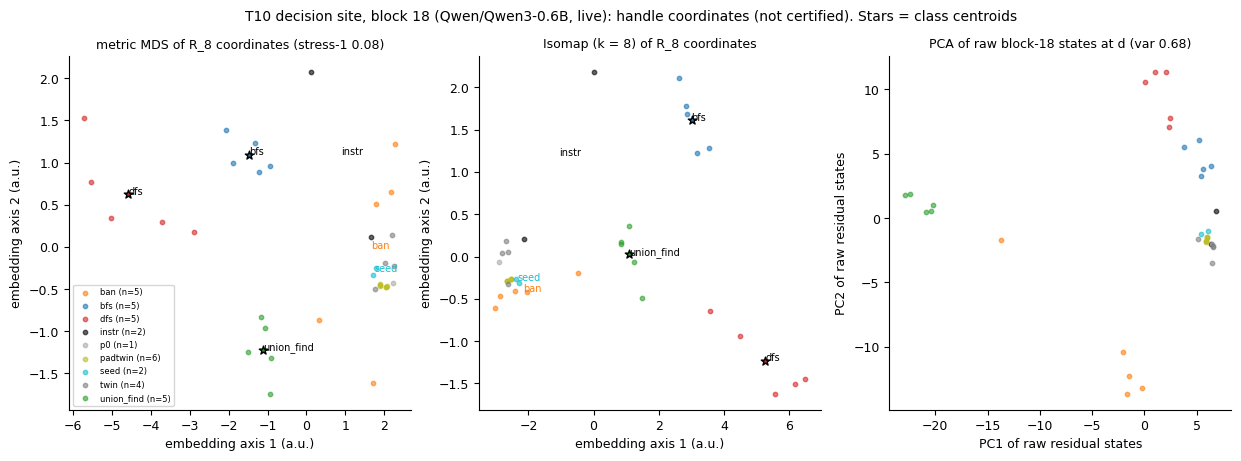

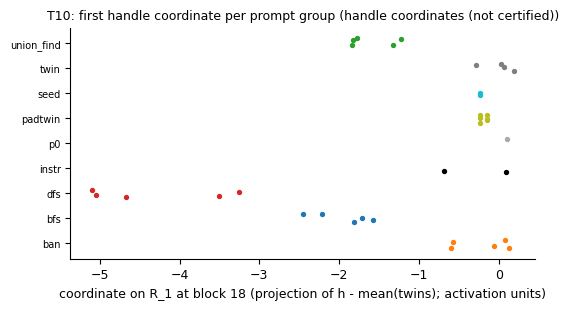

MDS stress-1: 0.081
mean Isomap geodesic distance from the twins to each group (live R_8 coordinates):
  ban             1.65
  bfs             5.96
  dfs             8.05
  instr           1.97
  p0              0.52
  padtwin         0.53
  seed            0.49
  union_find      3.95


In [24]:
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False})
COL = {"bfs": "#1f77b4", "dfs": "#d62728", "union_find": "#2ca02c", "astar_gbfs": "#9467bd", "iddfs": "#8c564b",
       "twin": "#7f7f7f", "padtwin": "#bcbd22", "ban": "#ff7f0e", "top5": "#e377c2", "seed": "#17becf",
       "instr": "#000000", "p0": "#aaaaaa"}


def save(fig: Any, name: str) -> None:
    fig.savefig(FIGS / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIGS / f"{name}.png", dpi=180, bbox_inches="tight")
    plt.show()  # notebook: draw inline before closing
    plt.close(fig)


def group_of(r: dict[str, Any]) -> str:
    k = r["kind"]
    if k == "forced":
        return r["Y"]
    if k in ("seed_rand1", "seed_rand2"):
        return "seed"
    if k in ("instr_new", "instr_novel"):
        return "instr"
    return k


def f3_geometry(unit: str, verdict: str | None, H: dict[str, torch.Tensor], R: torch.Tensor, P: dict, L: int,
                cnt: dict[str, int], tag: str = "") -> dict[str, Any] | None:
    """figures8.f3_geometry with its inputs passed in. The original reads L* from results/dec_<unit>.json, the seed-0
    map das_maps/<unit>_dec_L<L*>_seed0.pt, the states cache/states_<unit>_dec_trained.pt and the prompt file, and
    counts implemented programs (passing BASE + SRC rows of data/labels_<unit>.jsonl)."""
    keys = [k for k in P if k in H]
    X = torch.stack([H[k][L].float() for k in keys])                     # [n, D]
    tw = [i for i, k in enumerate(keys) if P[k]["kind"] == "twin"]
    mu = X[tw].mean(0)
    Z = ((X - mu) @ R).numpy()                                           # [n, 8] handle coordinates
    groups = [group_of(P[k]) for k in keys]
    D = np.linalg.norm(Z[:, None] - Z[None], axis=-1)
    mds = MDS(n_components=2, dissimilarity="precomputed", random_state=0, n_init=4, normalized_stress="auto")
    E = mds.fit_transform(D)
    dE = np.linalg.norm(E[:, None] - E[None], axis=-1)
    stress1 = float(np.sqrt(((D - dE) ** 2).sum() / (D ** 2).sum()))
    iso = Isomap(n_neighbors=8, n_components=2)
    Ei = iso.fit_transform(Z)
    geo = iso.dist_matrix_
    certified = verdict == "CERTIFIED VARIABLE"
    title = "causal manifold" if certified else "handle coordinates (not certified)"
    ug = sorted(set(groups))
    cents = {g: E[[i for i, x in enumerate(groups) if x == g]].mean(0) for g in ug}
    cls_names = [g for g in ug if g in ("bfs", "dfs", "union_find", "astar_gbfs", "iddfs")]
    gd = {}
    for a in ug:
        for b in ug:
            if a < b:
                ia = [i for i, x in enumerate(groups) if x == a]
                ib = [i for i, x in enumerate(groups) if x == b]
                gd[f"{a}|{b}"] = float(np.mean(geo[np.ix_(ia, ib)]))
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
    for ax, emb, name in ((axes[0], E, f"metric MDS of R_8 coordinates (stress-1 {stress1:.2f})"),
                          (axes[1], Ei, "Isomap (k = 8) of R_8 coordinates")):
        for g in ug:
            ix = [i for i, x in enumerate(groups) if x == g]
            ax.scatter(emb[ix, 0], emb[ix, 1], s=10, alpha=0.6, color=COL.get(g, "#333333"), label=f"{g} (n={len(ix)})")
        for g in cls_names:
            ix = [i for i, x in enumerate(groups) if x == g]
            c = emb[ix].mean(0)
            ax.scatter([c[0]], [c[1]], s=40 + 6 * cnt.get(g, 0), marker="*", color=COL.get(g), edgecolor="k",
                       zorder=5)
            ax.annotate(f"{g}: {cnt.get(g, 0)} impl." if cnt else g, c, fontsize=7)  # demo: no programs live
        for g in ("ban", "top5", "seed", "instr"):
            ix = [i for i, x in enumerate(groups) if x == g]
            if ix:
                c = emb[ix].mean(0)
                ax.annotate(g, c, fontsize=7, color=COL.get(g))
        ax.set_title(name, fontsize=9)
        ax.set_xlabel("embedding axis 1 (a.u.)")
        ax.set_ylabel("embedding axis 2 (a.u.)")
    axes[0].legend(fontsize=6, loc="best")
    pca = PCA(n_components=2).fit(X.numpy())
    Ep = pca.transform(X.numpy())
    for g in ug:
        ix = [i for i, x in enumerate(groups) if x == g]
        axes[2].scatter(Ep[ix, 0], Ep[ix, 1], s=10, alpha=0.6, color=COL.get(g, "#333333"), label=g)
    axes[2].set_title(f"PCA of raw block-{L} states at d (var {pca.explained_variance_ratio_.sum():.2f})", fontsize=9)
    axes[2].set_xlabel("PC1 of raw residual states")
    axes[2].set_ylabel("PC2 of raw residual states")
    fig.suptitle(f"{unit} decision site, block {L}: {title}. Stars = class centroids, size ~ implemented "
                 f"(passing BASE + SRC programs)" if cnt else
                 f"{unit} decision site, block {L} ({LIVE_MODEL_ID}, live): {title}. Stars = class centroids",
                 fontsize=10)
    save(fig, f"F3_geometry_{unit}{tag}")
    # handle coordinate 1 against class: a 1-D view of the actual coordinates
    fig, ax = plt.subplots(figsize=(6, 3))
    for j, g in enumerate(ug):
        ix = [i for i, x in enumerate(groups) if x == g]
        ax.scatter(Z[ix, 0], np.full(len(ix), j) + np.random.default_rng(j).uniform(-0.2, 0.2, len(ix)), s=8,
                   color=COL.get(g, "#333333"))
    ax.set_yticks(range(len(ug)))
    ax.set_yticklabels(ug, fontsize=7)
    ax.set_xlabel(f"coordinate on R_1 at block {L} (projection of h - mean(twins); activation units)")
    ax.set_title(f"{unit}: first handle coordinate per prompt group ({title})", fontsize=9)
    save(fig, f"F3b_handle_axis_{unit}{tag}")
    return {"unit": unit, "L": L, "mds_stress1": stress1, "isomap_mean_geodesic_between_groups": gd,
            "implemented_counts": cnt, "title": title, "n_prompts": len(keys),
            "group_centroids_mds": {g: cents[g].tolist() for g in ug}}


geo_live = f3_geometry("T10", None, site.H, fits[0]["R"], P, Lstar, {}, tag="_live")
print("MDS stress-1:", round(geo_live["mds_stress1"], 3))
print("mean Isomap geodesic distance from the twins to each group (live R_8 coordinates):")
for g in sorted({group_of(P[k]) for k in P}):
    if g != "twin":
        k_ = "|".join(sorted([g, "twin"]))
        print(f"  {g:11s} {geo_live['isomap_mean_geodesic_between_groups'][k_]:8.2f}")

## Results: summary table and figure

The table sets the recorded Qwen3-8B decision site (the artifact's numbers, recomputed in Part 1 where the rows are shipped) beside the live toy replay on Qwen3-0.6B (Part 2). The figure panels:
- **(a)** Qwen3-8B, recorded: share of CRN slots per arm whose program is **labelled** as the target (hatched) and that also **passes the hidden tests** (solid). DAS reaches DFS almost always and BFS mostly in name only.
- **(b) / (d)** The block scan of each model: the full-state exchange Δ at d (grey) and the rank-1 CV recovery (red), with the rule-chosen L*.
- **(c)** Held-out recovery by rank, with 95% two-way cluster CIs, against the random-subspace 95th percentile (c1), for both models.
- **(e)** The live per-pair view of recovery: each held-out pair's DAS Δ against its full-state Δ. Points above the diagonal are overshoot.
- **(f)** The two controls that decide K2. The bars give how much of the true fit's effect survives with **wrong labels** (c2) or an **untrained network** (c3). Above the dashed line, the site fails.

| quantity | Qwen3-8B, recorded (GPU) | Qwen/Qwen3-0.6B, live toy replay (CPU) | committed rule |
|---|---|---|---|
| block L* / rank k* | 22 / 4 | 18 / 8 | scan rule / smallest k within 90% of the best |
| TF recovery at k* (95% CI) | 8.43 (5.94 to 11.30) | 1.28 (1.09 to 1.47) | V0: ≥ 0.5, CI low > 0.25 |
| mean Δmargin: DAS vs full state (nats) | 17.37 vs 2.06 | 1.81 vs 1.41 |  |
| OFF-MANIFOLD flag | True | False | recovery > 1.5 |
| c1 random subspaces: median recovery at k* | -0.005 | 0.012 | ≤ 0.05 |
| c2 label controls: ratio to the true fit | 0.87, 0.63, 0.77 | 0.88, 0.73, 1.13 | ≤ 0.10 |
| c3 random-init network: ratio | 0.69 | 0.50 | ≤ 0.25 |
| c4 reverse: recovery | -2.72 | 0.69 | ≥ 0.5 |
| c5 retention on 64 twin PCs | 0.18 | 0.07 | ≥ 0.5 |
| c6 variance share (random p95) | 0.0076 (0.0016) | 0.0108 (0.0125) | > random p95 |
| c7 median first cosine (random p99) | 0.87 (0.07) | 0.40 (0.20) | ≥ 0.5 and > p99 |
| generation: correct DAS programs, target bfs / dfs | 5/30 / 29/30 (RAND 0 / 0) | not run | McNemar DAS > RAND, pass ratio ≥ 0.8 |
| verdict | **NO HANDLE**; K2 **DISCONFIRMED** (p_K2 = 0.037) | TF + controls only (no generation) | V0 + c1-c7 |

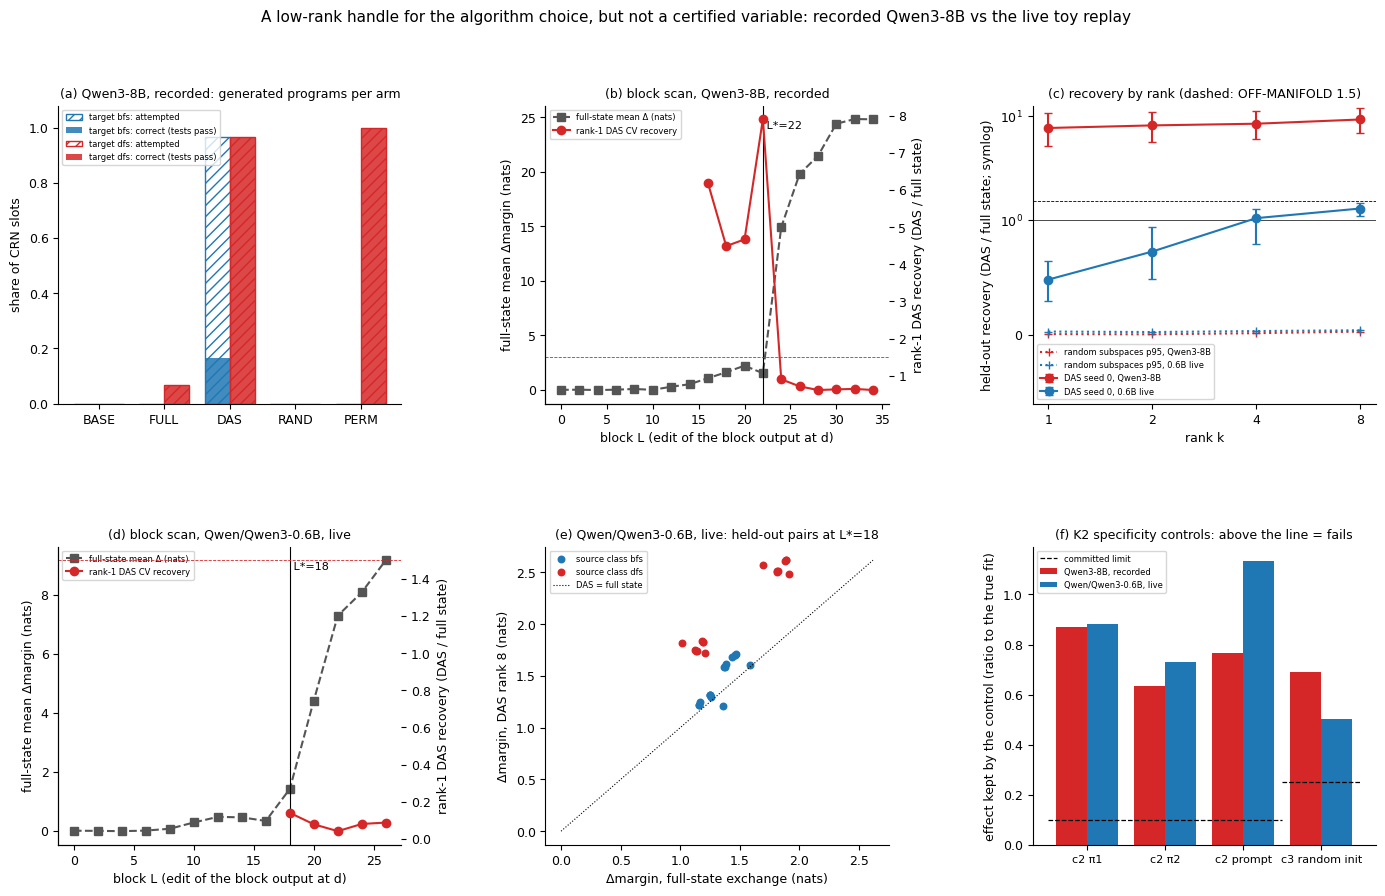

In [25]:
# ---------------- summary table: the recorded Qwen3-8B decision site vs the live toy replay ----------------
def site_row(d: dict[str, Any], rinit: dict[str, Any] | None) -> dict[str, str]:
    """Headline numbers of one decision site from its dec_*.json dict (string keys) and its c3 dict."""
    ks = str(d["k_star"])
    m = d["main"]
    c2r = [v["ratio_to_true_fit"] for v in d["c2"].values() if isinstance(v, dict) and "ratio_to_true_fit" in v]
    c6t = d["c6"]["twins"]
    return {"block L* / rank k*": f"{d['L_star']} / {d['k_star']}",
            "TF recovery at k* (95% CI)": f"{f(m['recovery'])} ({f(m['ci95'][0])} to {f(m['ci95'][1])})",
            "mean Δmargin: DAS vs full state (nats)": f"{f(m['mean_delta_edit'])} vs {f(m['mean_delta_full'])}",
            "OFF-MANIFOLD flag": str(d["off_manifold_flag"]),
            "c1 random subspaces: median recovery at k*": f(d["c1"][ks]["median"], 3),
            "c2 label controls: ratio to the true fit": ", ".join(f(x) for x in c2r),
            "c3 random-init network: ratio": f(rinit.get("ratio")) if rinit else "not run",
            "c4 reverse: recovery": f(d["c4"].get("recovery")),
            "c5 retention on 64 twin PCs": f(d["c5"]["twins"].get("retention")),
            "c6 variance share (random p95)": f"{f(c6t['share'], 4)} ({f(c6t['random_p95'], 4)})",
            "c7 median first cosine (random p99)": f"{f(d['c7'].get('median_first_cosine'))} "
                                                   f"({f(d['c7'].get('random_p99'))})"}


rule = {"block L* / rank k*": "scan rule / smallest k within 90% of the best",
        "TF recovery at k* (95% CI)": "V0: ≥ 0.5, CI low > 0.25", "mean Δmargin: DAS vs full state (nats)": "",
        "OFF-MANIFOLD flag": "recovery > 1.5", "c1 random subspaces: median recovery at k*": "≤ 0.05",
        "c2 label controls: ratio to the true fit": "≤ 0.10", "c3 random-init network: ratio": "≤ 0.25",
        "c4 reverse: recovery": "≥ 0.5", "c5 retention on 64 twin PCs": "≥ 0.5",
        "c6 variance share (random p95)": "> random p95", "c7 median first cosine (random p99)": "≥ 0.5 and > p99"}
row_8b, row_live = site_row(tf_T10, rinit_T10), site_row(res_live, rinit_live)
_g = gen_T10_dec["classes"]
md = ["| quantity | Qwen3-8B, recorded (GPU) | " + LIVE_MODEL_ID + ", live toy replay (CPU) | committed rule |",
      "|---|---|---|---|"]
md += [f"| {k} | {row_8b[k]} | {row_live[k]} | {rule[k]} |" for k in row_8b]
md.append(f"| generation: correct DAS programs, target bfs / dfs | {_g['bfs']['arms']['DAS']['correct_target']}/30 / "
          f"{_g['dfs']['arms']['DAS']['correct_target']}/30 (RAND {_g['bfs']['arms']['RAND']['correct_target']} / "
          f"{_g['dfs']['arms']['RAND']['correct_target']}) | not run | McNemar DAS > RAND, pass ratio ≥ 0.8 |")
md.append(f"| verdict | **{verdicts['T10-dec']['verdict']}**; K2 **{K2['status']}** (p_K2 = {K2['p_K2']:.3f}) | "
          f"TF + controls only (no generation) | V0 + c1-c7 |")
display(Markdown("\n".join(md)))

# ---------------- summary figure ----------------
fig, axes = plt.subplots(2, 3, figsize=(17, 9.6))
fig.subplots_adjust(hspace=0.48, wspace=0.42)
# (a) recorded generation outcomes per arm
ax = axes[0, 0]
arms = ["BASE", "FULL", "DAS", "RAND", "PERM"]
x = np.arange(len(arms))
w = 0.38
for j, c in enumerate(("bfs", "dfs")):
    t = gen_T10_dec["classes"][c]["arms"]
    ax.bar(x + (j - 0.5) * w, [t[a]["attempted_target"] / t[a]["n"] for a in arms], w, color="none",
           edgecolor=COL[c], hatch="///", label=f"target {c}: attempted")
    ax.bar(x + (j - 0.5) * w, [t[a]["correct_target"] / t[a]["n"] for a in arms], w, color=COL[c], alpha=0.85,
           label=f"target {c}: correct (tests pass)")
ax.set_xticks(x)
ax.set_xticklabels(arms)
ax.set_ylim(0, 1.08)
ax.set_ylabel("share of CRN slots")
ax.set_title("(a) Qwen3-8B, recorded: generated programs per arm", fontsize=9)
ax.legend(fontsize=6, loc="upper left")
# (b) recorded scan profile (F1, Qwen3-8B) and (d) live scan profile
for ax, sc_, Ls_, name in ((axes[0, 1], data["metadata"]["scan_T10"], tf_T10["L_star"], "Qwen3-8B, recorded"),
                           (axes[1, 0], res_live["scan"], res_live["L_star"], f"{LIVE_MODEL_ID}, live")):
    sc_ = {int(k): v for k, v in sc_.items()}
    bl = sorted(sc_)
    ax.plot(bl, [sc_[l]["full_state_mean_delta_held96"] for l in bl], "s--", color="#555555",
            label="full-state mean Δ (nats)")
    ax.set_xlabel("block L (edit of the block output at d)")
    ax.set_ylabel("full-state mean Δmargin (nats)")
    ax2 = ax.twinx()
    ax2.plot(bl, [np.nan if sc_[l]["cv_median_recovery"] is None else sc_[l]["cv_median_recovery"] for l in bl], "o-",
             color="#d62728", label="rank-1 DAS CV recovery")
    ax2.axhline(OFF_MANIFOLD, color="#d62728", lw=0.6, ls="--")
    ax2.set_ylabel("rank-1 DAS recovery (DAS / full state)")
    ax.axvline(Ls_, color="k", lw=0.8)
    ax.text(Ls_, ax.get_ylim()[1] * 0.92, f" L*={Ls_}", fontsize=8)
    h1, l1 = ax.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, fontsize=6, loc="upper left")
    ax.set_title(f"({'b' if 'recorded' in name else 'd'}) block scan, {name}", fontsize=9)
# (c) recovery by rank vs random subspaces, both models
ax = axes[0, 2]
ks = [1, 2, 4, 8]
for d, name, col in ((tf_T10, "Qwen3-8B", "#d62728"), (res_live, "0.6B live", "#1f77b4")):
    rr = np.array([d["recovery_by_rank"][str(k)]["recovery"] for k in ks], float)
    lo = np.array([d["recovery_by_rank"][str(k)]["ci95"][0] for k in ks], float)
    hi = np.array([d["recovery_by_rank"][str(k)]["ci95"][1] for k in ks], float)
    ax.errorbar(ks, rr, yerr=[rr - lo, hi - rr], fmt="o-", color=col, capsize=3, label=f"DAS seed 0, {name}")
    ax.plot(ks, [d["c1"][str(k)]["p95"] for k in ks], "+:", color=col, label=f"random subspaces p95, {name}")
ax.axhline(1.0, color="k", lw=0.5)
ax.axhline(OFF_MANIFOLD, color="k", lw=0.6, ls="--")
ax.set_xscale("log", base=2)
ax.set_yscale("symlog", linthresh=1.0)  # linear below 1, log above: both models on one axis
ax.set_xticks(ks)
ax.set_xticklabels(ks)
ax.set_xlabel("rank k")
ax.set_ylabel("held-out recovery (DAS / full state; symlog)")
ax.set_title("(c) recovery by rank (dashed: OFF-MANIFOLD 1.5)", fontsize=9)
ax.legend(fontsize=6)
# (e) live per-pair Delta: DAS at k* vs the full-state exchange
ax = axes[1, 1]
_rows = [r for r in tf_rows if r["fit"] == "seed0" and r["rank_k"] == res_live["k_star"]]
for c in classes:
    _xy = [(r["delta_full"], r["delta"]) for r in _rows if r["class_src"] == c]
    if _xy:
        ax.scatter(*zip(*_xy), s=22, color=COL[c], label=f"source class {c}")
_v = [r["delta_full"] for r in _rows] + [r["delta"] for r in _rows]
ax.plot([min(_v + [0]), max(_v)], [min(_v + [0]), max(_v)], "k:", lw=0.8, label="DAS = full state")
ax.set_xlabel("Δmargin, full-state exchange (nats)")
ax.set_ylabel(f"Δmargin, DAS rank {res_live['k_star']} (nats)")
ax.set_title(f"(e) {LIVE_MODEL_ID}, live: held-out pairs at L*={res_live['L_star']}", fontsize=9)
ax.legend(fontsize=6)
# (f) the specificity controls of K2: c2 and c3 ratios against their committed limits
ax = axes[1, 2]
names = ["c2 π1", "c2 π2", "c2 prompt", "c3 random init"]
v8 = [tf_T10["c2"][n]["ratio_to_true_fit"] for n in ("pi1", "pi2", "prompt")] + [rinit_T10["ratio"]]
vl = [(res_live["c2"].get(n) or {}).get("ratio_to_true_fit") for n in ("pi1", "pi2", "prompt")] + \
     [rinit_live["ratio"] if rinit_live else None]
x = np.arange(len(names))
ax.bar(x - 0.2, [np.nan if v is None else v for v in v8], 0.4, color="#d62728", label="Qwen3-8B, recorded")
ax.bar(x + 0.2, [np.nan if v is None else v for v in vl], 0.4, color="#1f77b4", label=f"{LIVE_MODEL_ID}, live")
ax.hlines(THRESH["c2_ratio_max"], -0.5, 2.5, colors="k", linestyles="--", lw=0.9, label="committed limit")
ax.hlines(THRESH["c3_ratio_max"], 2.5, 3.5, colors="k", linestyles="--", lw=0.9)
ax.axhline(0, color="k", lw=0.5)
ax.set_xticks(x)
ax.set_xticklabels(names, fontsize=8)
ax.set_ylabel("effect kept by the control (ratio to the true fit)")
ax.set_title("(f) K2 specificity controls: above the line = fails", fontsize=9)
ax.legend(fontsize=6)
fig.suptitle("A low-rank handle for the algorithm choice, but not a certified variable: recorded Qwen3-8B vs the "
             "live toy replay", fontsize=11)
save(fig, "F_summary")

## Takeaways

**Part 1, the recorded run.** On the shipped Qwen3-8B cells, the artifact's own `gen_tables` and `verdict` rebuild the recorded generation table exactly. They reproduce the T10 verdict (NO HANDLE by the pooled rule) and **K2 = DISCONFIRMED, p_K2 = 0.037**:
- A rank-4 edit at the decision token turns union-find into **correct DFS in 29/30 slots** (random subspace: 0/30). Toward BFS the model writes BFS in 29/30 slots, but only 5 programs pass the tests.
- Maps fitted to permuted labels keep 0.63-0.87 of the effect (c2), and a random-init network keeps 0.69 (c3).
- The edit overshoots the full-state exchange 8× (OFF-MANIFOLD).

**Part 2, the live toy replay on Qwen3-0.6B.** These numbers come from the run saved in this notebook. At toy scale they are illustrative, not estimates.
- **Same default.** At the decision token the neutral twins put 0.61 on union-find (`' find'`), and forced prompts adhere: BFS 0.79, DFS 0.95, union-find 1.00. The class is written into d only from block 18 on, where the full-state Δ first reaches 1 nat, so the scan rule picks L* = 18.
- **A handle, not off-manifold here.** Rank-8 DAS recovers 1.28× the full-state effect on 32 held-out pairs (95% CI 1.09-1.47). Random subspaces recover about 0, so c1 passes.
- **The same specificity failure as Qwen3-8B.** The two controls that disconfirmed K2 also fail on this 13× smaller model of the same family:
  - label-permuted refits keep 0.73-1.13 of the effect (c2, limit 0.10);
  - a randomly initialised network keeps 0.50 (c3, limit 0.25).

  c5 (0.07), c6 and c7 (first cosine 0.40 across three seeds) also fail; c4 passes.
- **Prompts aimed at novelty barely move the decision state.**
  - The two seed strings leave P(union-find) at d where the twins have it (0.67 and 0.59, against 0.61).
  - The long novelty instruction lowers it to 0.44, but the mass goes to tokens outside all three classes (0.47), not to BFS or DFS.
  - The five union-find bans *raise* the union-find tokens to 0.94 at the decision token. These are teacher-forced readings with the opening prefilled, not generated programs.
  - In the fitted subspace's coordinates (MDS / Isomap), the seeds and the empty spec sit inside the twin cluster, the bans and novelty instructions just outside it, and the forced clusters far away. In the recorded Qwen3-8B geometry, the seeds and both novelty instructions sit with the twins and the bans just outside.

**For "can we make an LLM write a different, or novel, algorithm?"** A low-rank edit at one token can force a *known* alternative (DFS), but the fitted subspace is a steering handle rather than a variable that holds the model's choice. Novelty instructions and random seed strings do not move the decision state toward any alternative, let alone a new one. The recorded run found 0 'other' programs among 1,857 correct ones.

To run at the original scale, use `method.py` with Qwen3-8B on a 23 GB GPU (see the config cell for every scaled-down value).